![Banner](../../../../Images/Banner/07_remote_sensing/09_13_banner_rs_capstones.png)


# Mapping Shrimp Ghers in Coastal Bangladesh with a 2025–2026 Sentinel-1 Time Series and Sentinel-2

In the southwest coast of Bangladesh (Khulna, Satkhira and Bagerhat districts), much of the land is managed as **ghers**: shallow ponds surrounded by earth dikes, flooded with brackish tidal water to grow black tiger shrimp (*Penaeus monodon*).


## Overview

Many farmers rotate shrimp in the dry season (about December–July) with salt-tolerant **Aman rice** in the monsoon (August–December). Other ghers hold water all year. Clouds cover the delta for much of the monsoon, so optical images see little of the rice phase. Sentinel-1 C-band SAR sees through clouds, and open water is the darkest surface it records, which makes a SAR time series well suited to mapping ghers and to telling the two management systems apart.

In this notebook we:

1. read the AOI (`AOI.kml`, a Sentinel-1 frame covering the southwest coast and the Sundarbans) and **search the Microsoft Planetary Computer** for terrain-corrected Sentinel-1 (`sentinel-1-rtc`, γ⁰, 10 m) on **relative orbit 150** from July 2025 to July 2026;
2. download the series once, at **200 m for the whole frame** (regional context) and at **20 m for a study window** over the gher belt of the three districts, and cache it on disk;
3. build two cloud-free **Sentinel-2 dry-season composites** (mid-November–December 2025 and February–mid-April 2026);
4. filter speckle with a multi-temporal filter and study the **backscatter signatures** of rivers, ghers, rice, mangrove, trees and buildings;
5. separate **rivers from ghers**, then map **year-round ghers**, **shrimp–rice rotation ghers** and rice with transparent rules, and date the **draining and refilling** of the ponds;
6. compare the rules with **k-means, Random Forest (Sentinel-1 alone and with Sentinel-2) and a TempCNN** trained on spatially held-out blocks;
7. clean the result, vectorise the gher patches, and report areas and timing by district.

**The gher calendar covered by the series**

| Period | What happens in a gher | What the radar sees |
|---|---|---|
| **Jul – Nov 2025** | rotation ghers: rainwater flushes the salt, Aman rice is transplanted and grows; year-round ghers: shrimp, prawn or fish | rotation: dark in July, VH rises with the rice canopy; year-round: dark |
| **Dec 2025 – Jan 2026** | rice harvested; ponds drained, dried, ploughed and limed | the bare, wet pond floor is brighter than water: the **drain hump** |
| **Feb – Jun 2026** | ponds filled with brackish water and stocked with shrimp post-larvae | dark (open water) |
| **Jul 2026** | shrimp harvested; monsoon starts the next rice cycle | dark |

**Study-area note.** `AOI.kml` is the footprint of a whole Sentinel-1 frame (about 280 × 200 km, mostly Sundarbans and sea). The regional view uses all of it at 200 m. The field-scale analysis uses an 82 × 60 km window over the gher belt of Satkhira, Khulna and Bagerhat, from Tala and Dumuria in the north to Shyamnagar, Koyra and Mongla at the edge of the Sundarbans.


## Core concepts

### Learning objectives

After working through this notebook you will be able to:

- search a STAC catalogue for a single Sentinel-1 orbit, check the revisit and coverage of the series, and catch mosaic artefacts;
- build cloud-free Sentinel-2 median composites with the scene classification layer;
- explain why open water is dark in SAR, why gher dikes and drained ponds are bright, and how a pond's annual calendar shows in its VH series;
- separate river water from gher water with a water-frequency, history (JRC) and drain-hump test;
- write phenology rules with `geolattice.rsense.sar.apps.rice_map` and add gher rules for the dry season;
- train and evaluate pixel classifiers (`train_pixel_classifier`, a TempCNN) with spatial block splits, with and without optical features;
- say what the numbers do and do **not** prove when no field reference data exist.

### Contents

1. [Setup](#Setup)
2. [Why SAR for shrimp ghers: backscatter physics and pond signatures](#Why-SAR-for-shrimp-ghers:-backscatter-physics-and-pond-signatures)
3. [Area of interest and study window](#Area-of-interest-and-study-window)
4. [Searching the Planetary Computer: inventory of the scenes](#Searching-the-Planetary-Computer:-inventory-of-the-scenes)
5. [Downloading and caching the time series, reference layers and Sentinel-2 composites](#Downloading-and-caching-the-time-series,-reference-layers-and-Sentinel-2-composites)
6. [Regional view: the whole frame at 200 m](#Regional-view:-the-whole-frame-at-200-m)
7. [Loading the gher window, quality control and speckle filtering](#Loading-the-gher-window,-quality-control-and-speckle-filtering)
8. [Reference layers and temporal signatures](#Reference-layers-and-temporal-signatures)
9. [Temporal features and multi-temporal composites](#Temporal-features-and-multi-temporal-composites)
10. [Separating rivers from ghers](#Separating-rivers-from-ghers)
11. [Rule-based gher mapping and pond-preparation dates](#Rule-based-gher-mapping-and-pond-preparation-dates)
12. [Unsupervised classification of the time series](#Unsupervised-classification-of-the-time-series)
13. [Supervised classification with Random Forest: Sentinel-1 alone and with Sentinel-2](#Supervised-classification-with-Random-Forest:-Sentinel-1-alone-and-with-Sentinel-2)
14. [Temporal deep learning with a TempCNN](#Temporal-deep-learning-with-a-TempCNN)
15. [Comparing the maps, cleaning and vectorising](#Comparing-the-maps,-cleaning-and-vectorising)
16. [Area and timing statistics by district](#Area-and-timing-statistics-by-district)
17. [Writing the outputs](#Writing-the-outputs)
18. [Interpretation, caveats and recommended recipe](#Interpretation,-caveats-and-recommended-recipe)


## Task and evaluation design

- **Data:** Sentinel-1 IW GRD, VV + VH, radiometric terrain-corrected γ⁰ (Planetary Computer `sentinel-1-rtc`), one orbit (relative orbit 150, descending, about 06:00 local time), 32 dates. Sentinel-2 L2A for two dry-season median composites.
- **No field reference is available.** The data folder holds the AOI and the district boundaries, but no gher or crop polygons. We therefore use (a) **rules** on the SAR series for the gher and rice classes, (b) **ESA WorldCover 2021** for mangrove, trees and built-up, (c) **JRC Global Surface Water** for the long-term water record, and (d) the **Sentinel-2 composites** as an *independent* optical check of the rules.
- **What the supervised scores mean.** The Random Forest and the TempCNN are trained on labels derived from the rules and from WorldCover. Their held-out scores measure how well a model reproduces those labels on unseen spatial blocks. They are **not** accuracy against the truth. Section 18 spells out the consequences.
- **Splits:** spatial blocks of 2 km, with no block shared between train and test.


## Setup

**Installation.** This notebook needs installation option 6 (every GeoLattice module): `pip install "geolattice[all]"`. See "Installation options" in the GeoLattice README.

In [1]:
import re, time, json, warnings
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import xarray as xr
import geopandas as gpd
import rasterio
from rasterio import features as rfeat
from affine import Affine
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch
from shapely.geometry import Polygon, box, shape
from shapely.ops import unary_union
from scipy import ndimage as ndi

import pystac_client, planetary_computer as pc, odc.stac
from odc.geo.geobox import GeoBox

import geolattice
import geolattice.rsense.classify.image_classification as ic
from geolattice.rsense.sar import sentinel1 as s1, speckle, apps as sarapps

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})

print("GeoLattice", geolattice.__version__)

# the notebook runs from its own folder or from the repository root
HERE = Path.cwd()
CANDIDATES = [HERE / "../../../../Data/08_remote_sensing/08_11_Capstones" / "SAR_BD_Coastal_District",
              HERE / "Data/08_remote_sensing/08_11_Capstones/SAR_BD_Coastal_District"]
DATA = next(p for p in CANDIDATES if p.exists())
OUT = DATA.parent.parent / "outputs" / "shrimp_bangladesh"
CACHE = DATA / "cache"
for p in (OUT, CACHE):
    p.mkdir(parents=True, exist_ok=True)

CRS = "EPSG:32645"                      # UTM 45N: the zone of the three districts (88.9-90.0 °E)
STAC = "https://planetarycomputer.microsoft.com/api/stac/v1"
ORBIT = 150
START, END = "2025-07-01", "2026-07-31"
SEED = 42
rng = np.random.default_rng(SEED)
print("DATA:", DATA)
print("OUT :", OUT)

GeoLattice 0.3.35
DATA: /home/zia207/Github/GeoLattice/Tutorials/notebooks/09_remote_sensing/09_11_Capstones/data/SAR_BD_Coastal_District
OUT : /home/zia207/Github/GeoLattice/Tutorials/notebooks/09_remote_sensing/09_11_Capstones/outputs/shrimp_bangladesh


## Why SAR for shrimp ghers: backscatter physics and pond signatures

### What the sensor measures

Sentinel-1 is a C-band (5.405 GHz, λ ≈ 5.6 cm) synthetic-aperture radar. In Interferometric Wide (IW) mode it records **VV** and **VH** polarisation. The product used here is the **radiometric terrain-corrected (RTC) γ⁰**, the backscatter coefficient normalised to the plane perpendicular to the look direction,

$$
\gamma^0 \;=\; \frac{\sigma^0}{\cos\theta_{\text{loc}}}\,,
$$

where $\sigma^0$ is the ground-range backscatter coefficient and $\theta_{\text{loc}}$ the local incidence angle from the DEM. The delta is flat, so the terrain correction is small, and with **one orbit** the incidence angle of a pixel is the same on every date. Values are stored as linear power and converted to decibels, $\gamma^0_{\mathrm{dB}} = 10\log_{10}\gamma^0$.

### Scattering in a gher landscape

| Surface | Dominant mechanism | VH (dB) | VV (dB) |
|---|---|---|---|
| Open water (river, gher), calm | specular reflection away from the sensor | ≈ −22 to −25 | ≈ −15 to −20 |
| Drained gher floor (wet mud, Dec–Jan) | rough, wet surface scattering | ≈ −20 to −16 | ≈ −13 to −10 |
| Aman rice in a gher or field | volume scattering in the canopy plus double bounce (stem–water) | rises from ≈ −21 to ≈ −15 | rises by 3–5 dB |
| Gher dikes with huts and trees | double bounce and volume scattering | bright lines at 10–20 m | bright |
| Mangrove (Sundarbans), homestead trees | strong volume scattering | ≈ −12 | ≈ −6 |
| Settlements | double bounce from buildings | ≈ −11 | ≈ −5 |

VH (cross-polarised) comes almost entirely from **volume scattering**, so it tracks the rice canopy and separates water from everything else. The water threshold used throughout is **VH < −18 dB**.

### Speckle and the equivalent number of looks

Radar is coherent, so a homogeneous surface gives a grainy signal called **speckle**. For multilooked intensity with $L$ equivalent looks, $\mathrm{CV}=\sigma_I/\mu_I = 1/\sqrt{L}$, and the ENL is estimated over a homogeneous area as $\widehat{\mathrm{ENL}}=\mu_I^2/\sigma_I^2$.

**Quegan & Yu (2001) multi-temporal filter.** For a co-registered stack of $N$ dates $I_k$, each date keeps its own local mean $E[I_k]$ while the speckle is averaged over all dates:

$$
J_k \;=\; \frac{E[I_k]}{N}\sum_{i=1}^{N}\frac{I_i}{E[I_i]} .
$$

Speckle drops by up to $\sqrt{N}$ without blurring the dikes as much as a single-date filter of the same strength, and each pixel keeps its own time series.

### The gher signature

For a pixel with VH series $y(t)$ and the water threshold $\tau_w=-18$ dB, define the **water fraction** in a period $P$,

$$
f_P \;=\; \frac{1}{|P|}\sum_{t\in P}\mathbf{1}\,[\,y(t)<\tau_w\,],
$$

for the Aman period $A$ (18 Aug–22 Nov 2025) and the shrimp period $S$ (14 Feb–26 Jun 2026), and the **drain hump**

$$
h \;=\; \max_{t\in D} y(t) \;-\; \operatorname{median}_{t\in S} y(t),
$$

where $D$ is the preparation period (4 Dec 2025–2 Feb 2026). Then:

- a **gher** has water through the shrimp season: $f_S \ge 0.7$;
- a **year-round gher** also holds water in the monsoon ($f_A \ge 0.7$) and shows no rice;
- a **shrimp–rice rotation gher** shows the **rice signature** in the monsoon: a minimum below −18 dB followed by a rise of at least 4 dB to a peak of at least −16 dB within 100 days (`sar.apps.rice_map`);
- a **river** has water in both seasons but **no drain hump** ($h<1.5$ dB) and a long water record (JRC occurrence ≥ 85 %), and is connected to wide channels;
- the date of $\max_D y$ estimates when the pond was **drained**, and the first later date with $y<\tau_w$ estimates when it was **refilled** for stocking (12-day precision).

### Sentinel-2 indices used as an independent check

With reflectances $\rho$ in the green (B03), red (B04), NIR (B08) and SWIR-1 (B11) bands,

$$
\mathrm{NDVI}=\frac{\rho_{NIR}-\rho_{red}}{\rho_{NIR}+\rho_{red}},\qquad
\mathrm{MNDWI}=\frac{\rho_{green}-\rho_{SWIR1}}{\rho_{green}+\rho_{SWIR1}} .
$$

MNDWI > 0 marks open water; NDVI > 0.3 marks a green canopy. A **rotation gher** should be green at the end of the Aman season (November–December) and wet in the shrimp season (February–April); a **year-round gher** should be wet in both.

### Classifiers used

**Random Forest** averages $B$ decision trees trained on bootstrap samples with random feature subsets, $\hat y(\mathbf{x})=\mathrm{mode}\{h_b(\mathbf{x})\}_{b=1}^{B}$.

**TempCNN** (Pelletier et al., 2019) applies 1-D convolutions along time to a sequence $\mathbf{X}\in\mathbb{R}^{T\times C}$ (here $T=32$ dates, $C=2$ bands):

$$
\mathbf{h}^{(l+1)}_t=\mathrm{ReLU}\!\Big(\mathrm{BN}\Big(\sum_{k=-\lfloor K/2\rfloor}^{\lfloor K/2\rfloor}\mathbf{W}^{(l)}_k\,\mathbf{h}^{(l)}_{t+k}+\mathbf{b}^{(l)}\Big)\Big),
$$

followed by a fully connected layer and a softmax. The kernels learn temporal shapes such as a dip or a hump wherever they occur in the season.


## Area of interest and study window


`AOI.kml` comes from a Sentinel-1 *map overlay* (a `gx:LatLonQuad` with the four corners of the frame), so `geopandas` cannot read it directly; we parse the four corners and build the polygon. The district boundaries come from `khulna_satkhira_bagerhat.geojson`.

The **study window** is a 20 m grid in UTM 45N (the zone of the three districts, and the grid Planetary Computer uses for this track). Its northern edge follows the frame boundary, so the northern tips of Satkhira and Khulna are outside the frame and outside the window.


AOI bounds (lon/lat): [88.231 21.071 90.947 23.001]
AOI area: 43,073 km²
districts: {'Bagerhat': 3643.6, 'Khulna': 3622.3, 'Satkhira': 3389.3} km²
window: Shape2d(x=4100, y=3000) pixels; 4,920 km²; inside AOI: True
window corners (lon/lat): [88.95  22.24  89.756 22.794]
share of each district inside the window: {'Bagerhat': 0.26, 'Khulna': 0.53, 'Satkhira': 0.54}


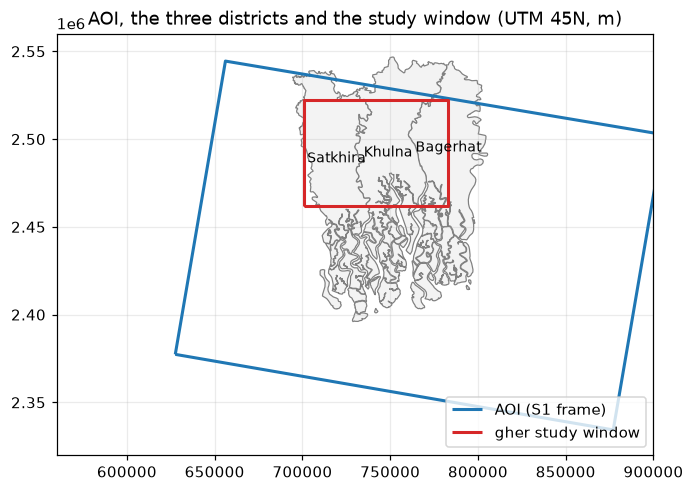

In [2]:
def read_quad_kml(path):
    # read the corner coordinates of a Sentinel-1 overlay KML
    txt = Path(path).read_text()
    pts = re.search(r"<coordinates>(.*?)</coordinates>", txt, re.S).group(1).split()
    return Polygon([tuple(map(float, p.split(",")[:2])) for p in pts])

aoi = read_quad_kml(DATA / "AOI.kml")
aoi_gdf = gpd.GeoDataFrame({"name": ["AOI"]}, geometry=[aoi], crs=4326)
aoi_utm = aoi_gdf.to_crs(CRS)
print("AOI bounds (lon/lat):", np.round(aoi.bounds, 3))
print(f"AOI area: {aoi_utm.area.iloc[0] / 1e6:,.0f} km²")

districts = gpd.read_file(DATA / "khulna_satkhira_bagerhat.geojson").to_crs(CRS)
print("districts:", dict(zip(districts.Name, districts.area_km2)), "km²")

# study window on a 20 m grid (pixel edges, UTM 45N): the gher belt of the three districts
WIN_BOUNDS = (701000, 2462000, 783000, 2522000)
WIN_RES = 20
win_gb = GeoBox.from_bbox(WIN_BOUNDS, CRS, resolution=WIN_RES)
win_poly = gpd.GeoDataFrame(geometry=[box(*WIN_BOUNDS)], crs=CRS)
print("window:", win_gb.shape, "pixels;", f"{win_poly.area.iloc[0] / 1e6:,.0f} km²;",
      "inside AOI:", bool(aoi_utm.geometry.iloc[0].contains(win_poly.geometry.iloc[0])))
print("window corners (lon/lat):", np.round(win_poly.to_crs(4326).total_bounds, 3))
dist_win = districts[districts.intersects(win_poly.geometry.iloc[0])]
print("share of each district inside the window:",
      {n: round(g.intersection(win_poly.geometry.iloc[0]).area / g.area, 2) for n, g in zip(districts.Name, districts.geometry)})

fig, ax = plt.subplots(figsize=(7, 6))
districts.plot(ax=ax, fc="#f3f3f3", ec="grey", lw=0.8)
for n, g in zip(districts.Name, districts.geometry):
    ax.annotate(n, g.representative_point().coords[0], ha="center", fontsize=9)
aoi_utm.boundary.plot(ax=ax, color="tab:blue", lw=2, label="AOI (S1 frame)")
win_poly.boundary.plot(ax=ax, color="tab:red", lw=2, label="gher study window")
ax.set_xlim(560000, 900000); ax.set_ylim(2.32e6, 2.56e6)
ax.set_title("AOI, the three districts and the study window (UTM 45N, m)"); ax.legend(loc="lower right")
plt.show()

## Searching the Planetary Computer: inventory of the scenes


We keep only items on **relative orbit 150** that intersect the AOI. Each date is made of two or three consecutive slices along the track; they are mosaicked when loaded (`groupby="solar_day"`). The table reports the share of the frame and of the study window covered on each date.


In [3]:
def search_s1():
    client = pystac_client.Client.open(STAC, modifier=pc.sign_inplace)
    items = client.search(collections=["sentinel-1-rtc"], intersects=aoi, datetime=f"{START}/{END}").items()
    by = {}
    for it in items:
        if it.properties["sat:relative_orbit"] == ORBIT:
            by.setdefault(it.datetime.date().isoformat(), []).append(it)
    return dict(sorted(by.items()))

by_date = search_s1()
rows = []
for d, its in by_date.items():
    cover = unary_union([shape(i.geometry) for i in its])
    rows.append({"date": pd.Timestamp(d), "platform": its[0].properties["platform"].upper(),
                 "slices": len(its), "orbit_state": its[0].properties["sat:orbit_state"],
                 "aoi_coverage": round(cover.intersection(aoi).area / aoi.area, 3),
                 "window_coverage": round(cover.intersection(win_poly.to_crs(4326).geometry.iloc[0]).area
                                          / win_poly.to_crs(4326).area.iloc[0], 3)})
inv = pd.DataFrame(rows).set_index("date")
inv["gap_days"] = inv.index.to_series().diff().dt.days
print(f"{len(inv)} dates on relative orbit {ORBIT} between {inv.index[0].date()} and {inv.index[-1].date()}")
print(inv.platform.value_counts().to_dict(), "| orbit state:", list(inv.orbit_state.unique()))
print("revisit gaps (days):", inv.gap_days.value_counts().sort_index().to_dict())
inv

32 dates on relative orbit 150 between 2025-07-13 and 2026-07-27
{'SENTINEL-1A': 29, 'SENTINEL-1D': 3} | orbit state: ['descending']
revisit gaps (days): {7.0: 1, 12.0: 29, 24.0: 1}


,platform,slices,orbit_state,aoi_coverage,window_coverage,gap_days
date,,,,,,
2025-07-13,SENTINEL-1A,2,descending,0.994,1.0,NaN
2025-07-25,SENTINEL-1A,2,descending,0.994,1.0,12.0
2025-08-06,SENTINEL-1A,2,descending,0.994,1.0,12.0
2025-08-18,SENTINEL-1A,2,descending,0.994,1.0,12.0
2025-08-30,SENTINEL-1A,2,descending,0.994,1.0,12.0
2025-09-11,SENTINEL-1A,2,descending,0.994,1.0,12.0
2025-09-23,SENTINEL-1A,3,descending,0.994,1.0,12.0
2025-10-05,SENTINEL-1A,3,descending,0.994,1.0,12.0
2025-10-17,SENTINEL-1A,3,descending,0.994,1.0,12.0


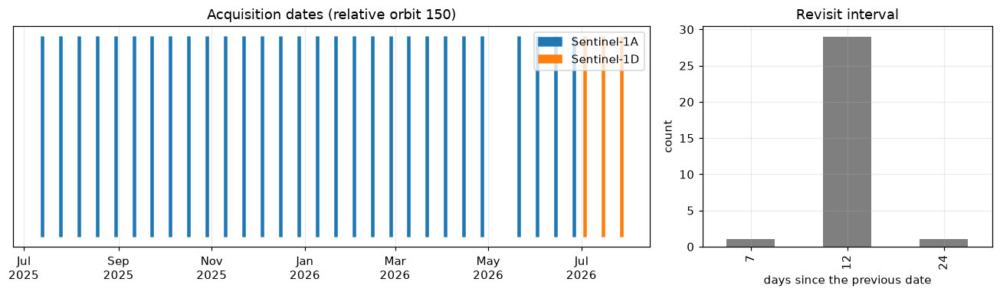

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6), gridspec_kw={"width_ratios": [2.2, 1]})
colors = {"SENTINEL-1A": "tab:blue", "SENTINEL-1D": "tab:orange", "SENTINEL-1C": "tab:green"}
ax[0].vlines(inv.index, 0, 1, color=[colors.get(p, "grey") for p in inv.platform], lw=3)
ax[0].set_yticks([]); ax[0].set_title(f"Acquisition dates (relative orbit {ORBIT})")
ax[0].xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
ax[0].legend(handles=[Patch(color=c, label=k.title()) for k, c in colors.items() if k in set(inv.platform)], loc="upper right")
inv.gap_days.dropna().astype(int).value_counts().sort_index().plot.bar(ax=ax[1], color="tab:grey")
ax[1].set_xlabel("days since the previous date"); ax[1].set_ylabel("count"); ax[1].set_title("Revisit interval")
plt.tight_layout(); plt.show()

**What the inventory shows.**

- The catalogue holds **32 dates** on this track between 13 July 2025 and 27 July 2026. Every date covers 99.4 % of the frame and the whole study window.
- The cadence is **12 days**. Sentinel-1A acquired until 26 June 2026 and **Sentinel-1D** from 3 July 2026; the one 7-day interval is the hand-over. The one 24-day interval is a missing acquisition on 9 May 2026, in the middle of the shrimp season, when ghers are full and a missing date costs little.
- On some dates the archive holds a third slice north of the frame. It does not change the window, but it matters for the regional mosaic (Section 6).


## Downloading and caching the time series, reference layers and Sentinel-2 composites


The RTC assets are cloud-optimised GeoTIFFs. For each date we load the slices with `odc.stac`, mosaic them, resample onto our grid by **averaging** (10 m → 20 m or 200 m; averaging also acts as multilooking) and write one compressed NetCDF per date. The next run reuses the cache, so the download happens once (about 1 minute for the 200 m frame and 12 minutes for the 20 m window, both for all 32 dates). Set `RUN_DOWNLOAD = False` to work offline once the cache exists.


In [5]:
RUN_DOWNLOAD = True
REG_RES = 200
REG_BOUNDS = tuple(np.round(np.array(aoi_utm.total_bounds) / REG_RES) * REG_RES)
reg_gb = GeoBox.from_bbox(REG_BOUNDS, CRS, resolution=REG_RES)
WIN_CACHE, REG_CACHE = CACHE / "rtc_gher_20m", CACHE / "aoi_rtc_200m"

def cache_file(cache, d):
    return cache / f"S1_{d.replace('-', '')}.nc"

def fetch_date(d, gb, cache):
    f = cache_file(cache, d)
    if f.exists():
        return f
    ds = odc.stac.load(by_date[d], bands=["vv", "vh"], geobox=gb, groupby="solar_day",
                       resampling="average", chunks={}).squeeze("time", drop=True)
    ds = ds.drop_vars([v for v in ds.coords if v not in ("x", "y")]).compute()
    ds.attrs = {"date": d.replace("-", ""), "slices": len(by_date[d]),
                "source": "Planetary Computer sentinel-1-rtc", "units": "gamma0 linear"}
    tmp = f.with_suffix(".tmp")
    ds.to_netcdf(tmp, engine="h5netcdf", encoding={v: {"zlib": True, "complevel": 4} for v in ("vv", "vh")})
    tmp.rename(f)
    return f

def fetch_all(gb, cache, workers=4):
    cache.mkdir(parents=True, exist_ok=True)
    todo = [d for d in by_date if not cache_file(cache, d).exists()]
    print(f"{cache.name}: {len(by_date) - len(todo)} cached, {len(todo)} to download")
    t0 = time.time()
    with ThreadPoolExecutor(workers) as ex:
        list(ex.map(lambda d: fetch_date(d, gb, cache), todo))
    if todo:
        print(f"  done in {time.time() - t0:.0f} s")

if RUN_DOWNLOAD:
    fetch_all(reg_gb, REG_CACHE)
    fetch_all(win_gb, WIN_CACHE)

aoi_rtc_200m: 32 cached, 0 to download
rtc_gher_20m: 32 cached, 0 to download


**Reference layers for the window**, on the same 20 m grid:

- **ESA WorldCover 2021** (10 m, resampled by the *mode*): tree cover (10), cropland (40), built-up (50), permanent water bodies (80), herbaceous wetland (90) and **mangroves (95)**;
- **JRC Global Surface Water occurrence** (30 m): the percentage of months with water, 1984–2021.


In [6]:
def fetch_reference():
    wc_f, jr_f = CACHE / "worldcover2021_20m_gher.nc", CACHE / "jrc_occurrence_20m_gher.nc"
    if wc_f.exists() and jr_f.exists():
        return wc_f, jr_f
    client = pystac_client.Client.open(STAC, modifier=pc.sign_inplace)
    bbox = tuple(win_poly.to_crs(4326).total_bounds)
    its = list(client.search(collections=["esa-worldcover"], bbox=bbox, datetime="2021-01-01/2021-12-31").items())
    wc = odc.stac.load(its, bands=["map"], geobox=win_gb, resampling="mode", chunks={}).isel(time=0).compute()["map"]
    wc.drop_vars("time", errors="ignore").to_dataset(name="worldcover").to_netcdf(wc_f)
    its = list(client.search(collections=["jrc-gsw"], bbox=bbox).items())
    jr = odc.stac.load(its, bands=["occurrence"], geobox=win_gb, resampling="nearest", chunks={}).isel(time=0).compute()["occurrence"]
    jr.drop_vars("time", errors="ignore").to_dataset(name="occurrence").to_netcdf(jr_f)
    return wc_f, jr_f

wc_f, jr_f = fetch_reference()
print(wc_f.name, jr_f.name)

worldcover2021_20m_gher.nc jrc_occurrence_20m_gher.nc


**Sentinel-2 dry-season composites.** We take every L2A scene with less than 10 % cloud in each period, mask clouds, cirrus and cloud shadows with the scene classification layer (SCL), and take the per-pixel **median** on the window grid. L2A digital numbers carry an offset of 1000 since processing baseline 04.00, so reflectance is (DN − 1000) / 10 000. The two periods bracket the gher calendar:

- **early dry, 15 Nov – 31 Dec 2025**: end of the Aman season, so rotation ghers carry a rice canopy;
- **late dry, 1 Feb – 15 Apr 2026**: ghers are filled with brackish water for shrimp.

Building the composites takes about 15 minutes the first time; later runs read the cached files.


In [7]:
S2_SEASONS = {"early dry (15 Nov - 31 Dec 2025)": ("2025-11-15", "2025-12-31"),
              "late dry (1 Feb - 15 Apr 2026)": ("2026-02-01", "2026-04-15")}
S2_BANDS = ["B02", "B03", "B04", "B08", "B11", "B12"]

def s2_composite(start, end, path, max_cloud=10):
    # median of cloud-masked L2A scenes on the window grid; reflectance = (DN - 1000) / 10000
    if path.exists():
        return xr.open_dataset(path).load(), None
    client = pystac_client.Client.open(STAC, modifier=pc.sign_inplace)
    its = list(client.search(collections=["sentinel-2-l2a"], bbox=tuple(win_poly.to_crs(4326).total_bounds),
                             datetime=f"{start}/{end}", query={"eo:cloud_cover": {"lt": max_cloud}}).items())
    ds = odc.stac.load(its, bands=S2_BANDS + ["SCL"], geobox=win_gb, groupby="solar_day",
                       resampling={"SCL": "nearest", "*": "average"}, chunks={"x": 1024, "y": 1024})
    ok = ~ds.SCL.isin([0, 1, 3, 8, 9, 10])          # no data, saturated, cloud shadow, clouds, cirrus
    refl = ((ds[S2_BANDS].where(ok & (ds.B04 > 0)) - 1000) / 10000).clip(0, 1)
    comp = refl.median("time").astype("float32").compute()
    comp["n_clear"] = ok.sum("time").astype("int16").compute()
    comp.attrs = {"scenes": len(its), "days": ds.sizes["time"], "period": f"{start}/{end}"}
    comp.to_netcdf(path, encoding={v: {"zlib": True, "complevel": 4} for v in comp.data_vars})
    return comp, len(its)

def s2_indices(c):
    nd = lambda a, b: (a - b) / (a + b + 1e-6)
    return xr.Dataset({"ndvi": nd(c.B08, c.B04), "mndwi": nd(c.B03, c.B11), "ndwi": nd(c.B03, c.B08)})

t0 = time.time()
S2 = {}
for k, (a, b) in S2_SEASONS.items():
    comp, n = s2_composite(a, b, CACHE / f"s2_median_{a}_{b}_20m.nc")
    S2[k] = xr.merge([comp, s2_indices(comp)])
    print(f"{k}: {comp.attrs['days']} days, clear observations per pixel: median {int(np.median(comp.n_clear))}, "
          f"min {int(comp.n_clear.min())}")
print(f"composites ready in {time.time() - t0:.0f} s")

early dry (15 Nov - 31 Dec 2025): 19 days, clear observations per pixel: median 19, min 15


late dry (1 Feb - 15 Apr 2026): 15 days, clear observations per pixel: median 15, min 10
composites ready in 3 s


## Regional view: the whole frame at 200 m


At 200 m each pixel averages 400 native 10 m pixels, so speckle is negligible and no filter is needed. The regional grid is the bounding box of the tilted frame. On dates without the third (northern) slice, the strip north of the frame is filled with near-zero values rather than "no data", which drags any regional mean down by several dB on those dates. We therefore set everything outside the frame footprint to NaN before averaging.


region 200 m: 32 dates, 1050 x 1392 px, NaN fraction 0.0000


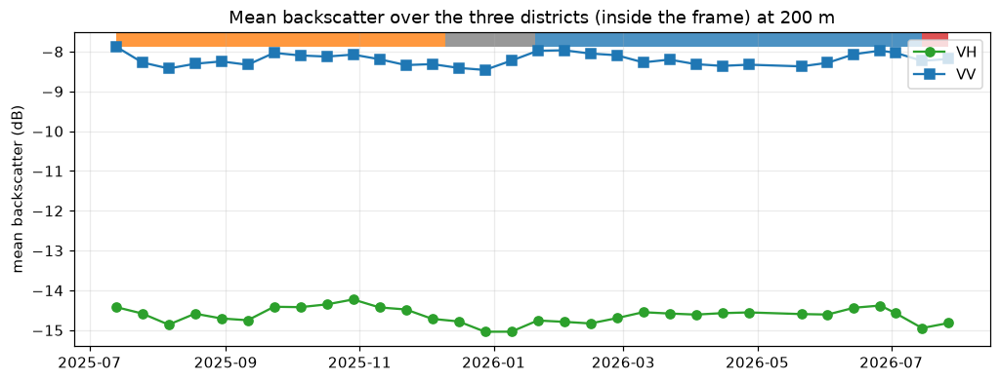

In [8]:
def load_stack(cache, label):
    fs = sorted(cache.glob("S1_*.nc"))
    t = pd.to_datetime([f.stem[3:] for f in fs], format="%Y%m%d")
    parts = [xr.open_dataset(f).load() for f in fs]
    ds = xr.concat(parts, dim=pd.Index(t, name="time"))
    ds = ds.rio.write_crs(CRS)
    print(f"{label}: {ds.sizes['time']} dates, {ds.sizes['y']} x {ds.sizes['x']} px, "
          f"NaN fraction {float(ds.vh.isnull().mean()):.4f}")
    return ds

reg = load_stack(REG_CACHE, "region 200 m")
# the regional grid is the bounding box of the tilted frame: outside the frame, and north of it on dates
# without the third slice, the mosaic holds fill values, so everything outside the frame is set to NaN
frame = rfeat.geometry_mask(aoi_utm.geometry, out_shape=(reg.sizes["y"], reg.sizes["x"]), transform=reg_gb.affine, invert=True)
reg = reg.where(xr.DataArray(frame, dims=("y", "x")) & (reg.vh > 0))
reg_vh = s1.to_db(reg.vh)
reg_vv = s1.to_db(reg.vv)
reg_vh.name, reg_vv.name = "vh_db", "vv_db"

def seasons_bar(ax):
    # coloured bars at the top of a time-series axis marking the gher calendar
    bars = [("Aman rice 2025", "2025-07-13", "2025-12-10", "tab:orange"),
            ("gher drained / prepared", "2025-12-10", "2026-01-20", "tab:grey"),
            ("shrimp culture 2026", "2026-01-20", "2026-07-15", "tab:blue"),
            ("Aman rice 2026", "2026-07-15", "2026-07-27", "tab:red")]
    for k, (name, a, b, c) in enumerate(bars):
        a, b = mdates.date2num(pd.Timestamp(a)), mdates.date2num(pd.Timestamp(b))
        ax.axvspan(a, b, ymin=0.955, ymax=1.0, color=c, alpha=0.8, lw=0)
    ax.legend(handles=[Patch(color=c, label=n) for n, _, _, c in bars], ncol=4, loc="lower center", fontsize=8)

fig, ax = plt.subplots(figsize=(11, 3.8))
in_dist = rfeat.geometry_mask(districts.geometry, out_shape=reg_vh.shape[1:], transform=reg_gb.affine, invert=True) & frame
ax.plot(reg_vh.time, np.nanmean(reg_vh.values[:, in_dist], 1), "o-", color="tab:green", label="VH")
ax.plot(reg_vv.time, np.nanmean(reg_vv.values[:, in_dist], 1), "s-", color="tab:blue", label="VV")
ax.set_ylabel("mean backscatter (dB)"); ax.set_title("Mean backscatter over the three districts (inside the frame) at 200 m")
seasons_bar(ax); ax.legend(loc="upper right")
plt.show()

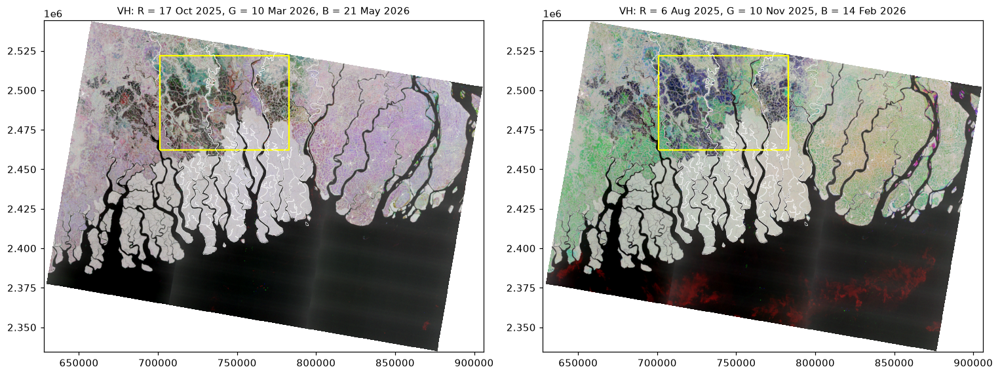

In [9]:
def rgb_composite(db, dates, lo=-26, hi=-8):
    # three dates in R, G, B; each stretched between lo and hi dB
    ch = [db.sel(time=pd.Timestamp(d), method="nearest").values for d in dates]
    return np.clip((np.dstack(ch) - lo) / (hi - lo), 0, 1)

COMP_A = ["2025-10-17", "2026-03-10", "2026-05-21"]     # Aman canopy, shrimp water, late shrimp season
COMP_B = ["2025-08-06", "2025-11-10", "2026-02-14"]
fig, ax = plt.subplots(1, 2, figsize=(14, 5.4))
ext = [float(reg.x.min()), float(reg.x.max()), float(reg.y.min()), float(reg.y.max())]
for a, dates, ttl in [(ax[0], COMP_A, "VH: R = 17 Oct 2025, G = 10 Mar 2026, B = 21 May 2026"),
                      (ax[1], COMP_B, "VH: R = 6 Aug 2025, G = 10 Nov 2025, B = 14 Feb 2026")]:
    a.imshow(rgb_composite(reg_vh, dates), extent=ext, origin="upper")
    aoi_utm.boundary.plot(ax=a, color="white", lw=1); win_poly.boundary.plot(ax=a, color="yellow", lw=1.5)
    districts.boundary.plot(ax=a, color="white", lw=0.5, alpha=0.8)
    a.set_xlim(ext[0], ext[1]); a.set_ylim(ext[2], ext[3]); a.set_title(ttl, fontsize=10); a.grid(False)
plt.tight_layout(); plt.show()

**How to read the composites.** Over the three districts the mean backscatter barely changes through the year (VH −14.2 to −15.0 dB, VV −7.9 to −8.4 dB). The landscape is a mosaic of ghers, rice and trees whose cycles cancel out, so the information is in the individual pixels, not the regional mean.

- **Left (R = 17 Oct 2025, G = 10 Mar 2026, B = 21 May 2026):** the gher belt of the window (yellow) is **black**: dark in the Aman season and through the shrimp season. Pixels that were bright in October (rice canopy) and dark in March (water) appear **red**. The **Sundarbans** in the south are uniformly bright (light grey) on all dates, and the rivers and estuaries are black.
- **Right (R = 6 Aug 2025, G = 10 Nov 2025, B = 14 Feb 2026):** the ghers are dark navy. Green tones east of the window are fields that were dark in August and bright in November, the Aman rice pattern.


## Loading the gher window, quality control and speckle filtering


In [10]:
win = load_stack(WIN_CACHE, "window 20 m")
T = win.sizes["time"]
times = win.time.values
print("grid:", win.sizes["y"], "x", win.sizes["x"], "| memory (vv+vh):", f"{(win.vv.nbytes + win.vh.nbytes) / 1e9:.1f} GB")
print("non-positive or missing values:", int(((win.vh <= 0) | win.vh.isnull()).sum()))

window 20 m: 32 dates, 3000 x 4100 px, NaN fraction 0.0000
grid: 3000 x 4100 | memory (vv+vh): 3.1 GB


non-positive or missing values: 0


### Quality check of the series

A scene-wide mean is dominated by water and crops, so it cannot reveal a calibration problem. The **Sundarbans mangrove** (ESA WorldCover class 95) has no crop or pond cycle, so we use it as a **stable target**. We compare its mean VH on each date with a rolling median and flag a date when the residual is both a robust outlier (more than 3 robust standard deviations) **and** larger than 0.5 dB. The second condition matters: the mangrove series is so smooth that its robust standard deviation is tiny, and a z-score alone would flag harmless deviations of 0.2 dB. The same series shows whether there is a step between **Sentinel-1A** and **Sentinel-1D**.


largest residual from the rolling median: 0.47 dB
stable target: 1,843,556 mangrove pixels (WorldCover 95)
flagged dates: none
mean VH over mangrove: S1A -11.97 dB, S1D -11.83 dB (difference +0.14 dB); overall SD 0.34 dB


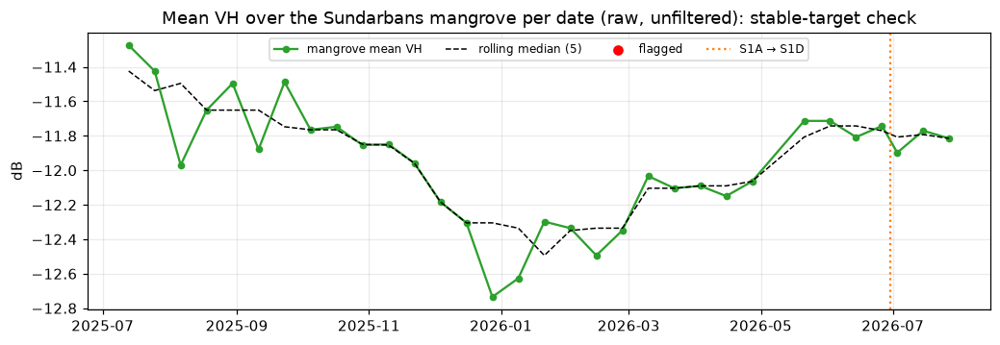

In [11]:
wc_arr = xr.open_dataset(wc_f).worldcover.values.astype("uint8")
stable = wc_arr == 95                     # mangrove (Sundarbans): no crop or gher cycle
stable_raw = 10 * np.log10(win.vh.values[:, stable].mean(1))
mean_raw = pd.Series(stable_raw, index=pd.DatetimeIndex(times))
roll = mean_raw.rolling(5, center=True, min_periods=3).median()
resid = mean_raw - roll
z = resid / (1.4826 * np.median(np.abs(resid - np.median(resid))))
flag = (z.abs() > 3) & (resid.abs() > 0.5)      # robust outlier AND a step large enough to matter
print(f"largest residual from the rolling median: {resid.abs().max():.2f} dB")
print(f"stable target: {stable.sum():,} mangrove pixels (WorldCover 95)")
print("flagged dates:", [d.date().isoformat() for d in mean_raw.index[flag]] or "none")
s1a = mean_raw[mean_raw.index < "2026-07-01"]; s1d = mean_raw[mean_raw.index >= "2026-07-01"]
print(f"mean VH over mangrove: S1A {s1a.mean():.2f} dB, S1D {s1d.mean():.2f} dB (difference {s1d.mean() - s1a.mean():+.2f} dB); "
      f"overall SD {mean_raw.std():.2f} dB")

fig, ax = plt.subplots(figsize=(11, 3.4))
ax.plot(mean_raw.index, mean_raw.values, "o-", ms=4, color="tab:green", label="mangrove mean VH")
ax.plot(roll.index, roll.values, "--", color="k", lw=1, label="rolling median (5)")
ax.scatter(mean_raw.index[flag], mean_raw[flag], color="red", zorder=3, label="flagged")
ax.axvline(pd.Timestamp("2026-06-30"), color="tab:orange", ls=":", label="S1A → S1D")
ax.set_ylabel("dB"); ax.set_title("Mean VH over the Sundarbans mangrove per date (raw, unfiltered): stable-target check")
ax.legend(ncol=4, fontsize=8)
plt.show()

No date is flagged: the largest residual from the rolling median is 0.47 dB. Mangrove VH drifts smoothly by about 1 dB over the year (wetter canopy in the monsoon), and the Sentinel-1D dates differ from the Sentinel-1A dates by only +0.14 dB, so the two platforms are treated as one series.

### Multi-temporal speckle filtering

We apply the Quegan & Yu filter (`multitemporal_speckle_filter`) with a 5 × 5 Lee spatial estimator to both polarisations, then compare one date before and after filtering, and with a single-date Lee filter of the same size. The ENL is measured over a homogeneous mangrove block of 30 × 30 pixels.


In [12]:
t0 = time.time()
vh_f = s1.multitemporal_speckle_filter(win.vh, spatial="lee", size=5)
vv_f = s1.multitemporal_speckle_filter(win.vv, spatial="lee", size=5)
print(f"filtered {T} dates x 2 polarisations in {time.time() - t0:.0f} s")
vh_db = s1.to_db(vh_f).astype("float32"); vv_db = s1.to_db(vv_f).astype("float32")
vh_db.name, vv_db.name = "vh_db", "vv_db"

filtered 32 dates x 2 polarisations in 68 s


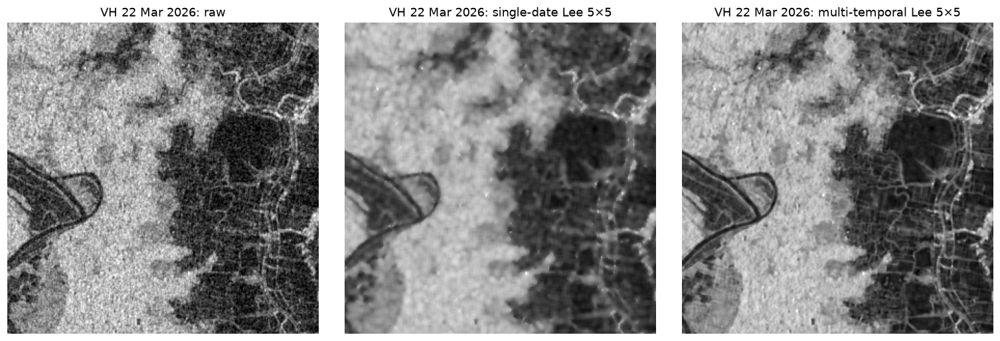

ENL over a homogeneous mangrove block (rows 2354:2384, cols 3861:3891):
  raw                      9.5
  single-date Lee         75.3
  multi-temporal Lee      55.1


In [13]:
k = int(np.argmin(np.abs(times - np.datetime64("2026-03-22"))))
r0, c0, n = 600, 1700, 300
sl = (slice(r0, r0 + n), slice(c0, c0 + n))
raw = win.vh.isel(time=k).values[sl]
single = speckle.lee(win.vh.isel(time=k).values, 5)[sl]
multi = vh_f.isel(time=k).values[sl]
fig, ax = plt.subplots(1, 3, figsize=(14, 4.6))
for a, im, t in zip(ax, [raw, single, multi], ["raw", "single-date Lee 5×5", "multi-temporal Lee 5×5"]):
    a.imshow(10 * np.log10(im), cmap="gray", vmin=-25, vmax=-8); a.set_title(f"VH 22 Mar 2026: {t}"); a.axis("off")
plt.tight_layout(); plt.show()

# homogeneous block: lowest coefficient of variation of the temporal mean among mangrove blocks
tm = win.vh.mean("time").values
best, bpos = np.inf, None
for _ in range(400):
    r, c = rng.integers(0, tm.shape[0] - 30), rng.integers(0, tm.shape[1] - 30)
    if (wc_arr[r:r + 30, c:c + 30] == 95).all():
        cv = tm[r:r + 30, c:c + 30].std() / tm[r:r + 30, c:c + 30].mean()
        if cv < best:
            best, bpos = cv, (r, c)
r, c = bpos
blk = (slice(r, r + 30), slice(c, c + 30))
enl = {"raw": speckle.enl_estimate(win.vh.isel(time=k).values[blk]),
       "single-date Lee": speckle.enl_estimate(speckle.lee(win.vh.isel(time=k).values, 5)[blk]),
       "multi-temporal Lee": speckle.enl_estimate(vh_f.isel(time=k).values[blk])}
print("ENL over a homogeneous mangrove block (rows %d:%d, cols %d:%d):" % (r, r + 30, c, c + 30))
for kk, vv_ in enl.items():
    print(f"  {kk:20s} {vv_:7.1f}")

Both filters raise the ENL far above that of the raw 20 m data. The single-date Lee filter gives the higher ENL, but the images show its cost: it blurs the **gher dikes** (the bright grid lines on the right) into a smudge. The multi-temporal filter keeps the dikes and the small ponds sharp, because it borrows information from the other 31 dates instead of from neighbouring pixels. ENL measures noise reduction only, not how well edges are kept.


## Reference layers and temporal signatures


In [14]:
jrc = xr.open_dataset(jr_f).occurrence.values.astype("float32")
jrc[jrc > 100] = 0                                  # 255 = no data (never water)
WC_NAMES = {10: "Tree cover", 20: "Shrubland", 30: "Grassland", 40: "Cropland", 50: "Built-up",
            60: "Bare / sparse", 80: "Permanent water", 90: "Herbaceous wetland", 95: "Mangroves"}
tab = pd.Series(wc_arr.ravel()).map(WC_NAMES).value_counts(normalize=True).mul(100).round(1)
print("WorldCover 2021 composition of the window (%):"); print(tab.to_string())

WorldCover 2021 composition of the window (%):
Cropland              34.1
Permanent water       28.7
Tree cover            18.9
Mangroves             15.0
Bare / sparse          1.6
Grassland              1.1
Built-up               0.4
Herbaceous wetland     0.2
Shrubland              0.0


WorldCover maps **28.7 %** of the window as *permanent water*, almost as much as cropland. The next figure shows that most of this "permanent water" is gher, not river.


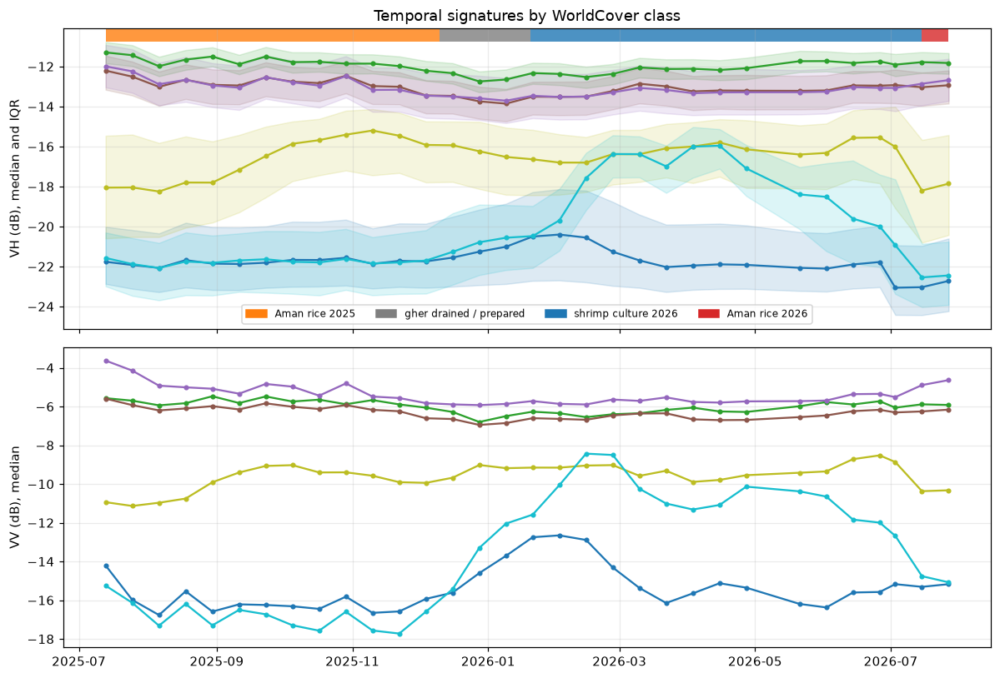

Permanent water (WC 80)      late-dry MNDWI (median) +0.32 | early-dry NDVI (median) -0.06
Cropland (WC 40)             late-dry MNDWI (median) -0.36 | early-dry NDVI (median) +0.41
Mangroves (WC 95)            late-dry MNDWI (median) -0.42 | early-dry NDVI (median) +0.78
Tree cover (WC 10)           late-dry MNDWI (median) -0.44 | early-dry NDVI (median) +0.66
Built-up (WC 50)             late-dry MNDWI (median) -0.36 | early-dry NDVI (median) +0.35
Herbaceous wetland (WC 90)   late-dry MNDWI (median) -0.34 | early-dry NDVI (median) +0.06


In [15]:
groups = {"Permanent water (WC 80)": wc_arr == 80, "Cropland (WC 40)": wc_arr == 40, "Mangroves (WC 95)": wc_arr == 95,
          "Tree cover (WC 10)": wc_arr == 10, "Built-up (WC 50)": wc_arr == 50, "Herbaceous wetland (WC 90)": wc_arr == 90}
cols = ["tab:blue", "tab:olive", "tab:green", "tab:brown", "tab:purple", "tab:cyan"]
fig, ax = plt.subplots(2, 1, figsize=(11, 7.5), sharex=True)
for (name, m), c in zip(groups.items(), cols):
    q = np.nanpercentile(vh_db.values[:, m], [25, 50, 75], axis=1)
    ax[0].plot(vh_db.time, q[1], "-o", ms=3, color=c, label=f"{name} (n={m.sum():,})")
    ax[0].fill_between(vh_db.time, q[0], q[2], color=c, alpha=0.15)
    ax[1].plot(vv_db.time, np.nanmedian(vv_db.values[:, m], axis=1), "-o", ms=3, color=c)
ax[0].set_ylabel("VH (dB), median and IQR"); ax[1].set_ylabel("VV (dB), median")
ax[0].legend(fontsize=8, ncol=2, loc="lower right", bbox_to_anchor=(1, 0.08)); ax[0].set_title("Temporal signatures by WorldCover class")
seasons_bar(ax[0])
plt.tight_layout(); plt.show()
for name, m in groups.items():
    print(f"{name:28s} late-dry MNDWI (median) {np.nanmedian(S2['late dry (1 Feb - 15 Apr 2026)'].mndwi.values[m]):+.2f} | "
          f"early-dry NDVI (median) {np.nanmedian(S2['early dry (15 Nov - 31 Dec 2025)'].ndvi.values[m]):+.2f}")

**Reading the signatures.**

- **WorldCover permanent water (blue)** sits near −22 dB VH from July to November, then rises in December–February (IQR up to about −18.5 dB) and falls back in March. Rivers do not drain, so this hump is the drying of the **ghers**: WorldCover labels the gher belt as water because it is wet for most of the year.
- **Cropland (olive)** is the Aman pattern: low in July–August (transplanting in standing water), a rise to about −15 dB in October–November, then a slow decline.
- **Mangroves, tree cover and built-up** stay high (−11 to −13 dB) on every date. VH alone does not separate them, so they are taken from WorldCover.
- **Herbaceous wetland** (0.2 % of the window) is flooded in the monsoon and rises in January–March.
- **Sentinel-2 agrees**: WorldCover water has a positive MNDWI in the late dry season, and mangrove and trees have the highest NDVI.


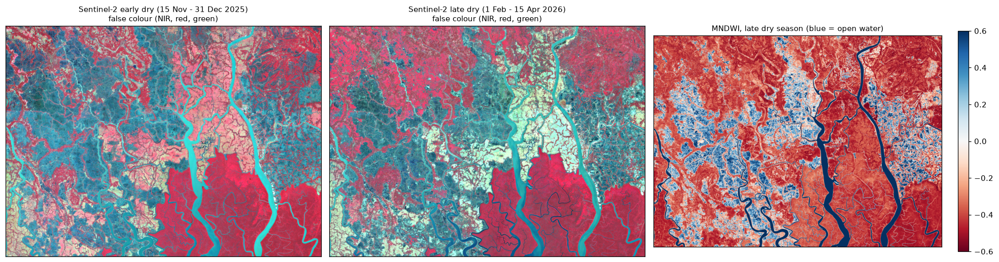

In [16]:
fc = lambda c: np.clip(np.dstack([c.B08, c.B04, c.B03]) / np.array([0.35, 0.15, 0.15]), 0, 1)
fig, ax = plt.subplots(1, 3, figsize=(18, 4.9))
ext_w = [float(win.x.min()), float(win.x.max()), float(win.y.min()), float(win.y.max())]
for a, (k_, comp) in zip(ax[:2], S2.items()):
    a.imshow(fc(comp), extent=ext_w); a.set_title(f"Sentinel-2 {k_}\nfalse colour (NIR, red, green)", fontsize=10)
im = ax[2].imshow(S2["late dry (1 Feb - 15 Apr 2026)"].mndwi, cmap="RdBu", vmin=-0.6, vmax=0.6, extent=ext_w)
ax[2].set_title("MNDWI, late dry season (blue = open water)", fontsize=10); plt.colorbar(im, ax=ax[2], fraction=0.035)
for a in ax:
    a.grid(False); a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()

In the **early dry** composite (left), the gher belt is dark blue-green (water), rice fields are pink-red (canopy) and the Sundarbans are deep red. The large rivers are bright cyan because they carry sediment. In the **late dry** composite (centre), the rice is gone. Some fields are pale (bare or saline soil), and the gher belt is still water; the MNDWI (right) shows the dense pattern of ponds in Satkhira, south Khulna and west Bagerhat.


## Temporal features and multi-temporal composites


Besides generic statistics of the VH series (mean, standard deviation, minimum, maximum, amplitude and their dates, plus VV and VH − VV), we compute the four gher variables of Section 2.4: the water fraction in the Aman and in the shrimp period, the Aman peak, and the drain hump.


['vh_mean', 'vh_std', 'vh_min', 'vh_max', 'vh_amp', 'vh_day_min', 'vh_day_max', 'vv_mean', 'vv_std', 'vhvv_mean', 'water_frac_aman', 'water_frac_shrimp', 'aman_peak', 'drain_hump']


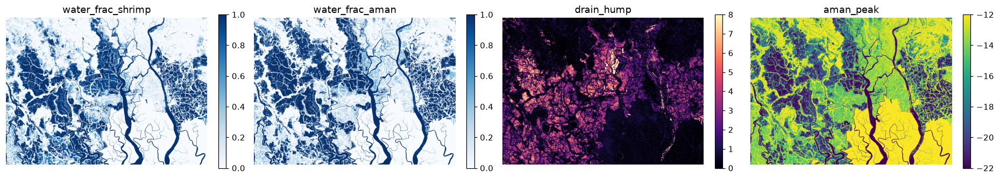

In [17]:
PERIODS = {"aman": ("2025-08-18", "2025-11-22"),      # Aman rice canopy (or monsoon water in year-round ghers)
           "prep": ("2025-12-04", "2026-02-02"),      # ghers drained, dried and limed
           "shrimp": ("2026-02-14", "2026-06-26")}    # ghers filled with brackish water and stocked
WATER_DB = -18.0

def temporal_features(vh, vv):
    # per-pixel statistics of the dB series, including the three gher-calendar periods
    t = vh.time.values.astype("datetime64[D]")
    days = (t - t[0]).astype(int).astype("float32")
    a = vh.values
    per = {k: vh.sel(time=slice(*v)) for k, v in PERIODS.items()}
    f = {"vh_mean": a.mean(0), "vh_std": a.std(0), "vh_min": a.min(0), "vh_max": a.max(0), "vh_amp": a.max(0) - a.min(0),
         "vh_day_min": days[a.argmin(0)], "vh_day_max": days[a.argmax(0)],
         "vv_mean": vv.values.mean(0), "vv_std": vv.values.std(0), "vhvv_mean": (vh.values - vv.values).mean(0),
         "water_frac_aman": (per["aman"] < WATER_DB).mean("time").values,
         "water_frac_shrimp": (per["shrimp"] < WATER_DB).mean("time").values,
         "aman_peak": per["aman"].max("time").values,
         "drain_hump": (per["prep"].max("time") - per["shrimp"].median("time")).values}
    tmpl = vh.isel(time=0, drop=True)
    return xr.Dataset({k: tmpl.copy(data=np.asarray(v, "float32")) for k, v in f.items()})

feat_stats = temporal_features(vh_db, vv_db)
print(list(feat_stats.data_vars))
fig, ax = plt.subplots(1, 4, figsize=(17, 4.2))
for a, (k, cm, lim) in zip(ax, [("water_frac_shrimp", "Blues", (0, 1)), ("water_frac_aman", "Blues", (0, 1)),
                                ("drain_hump", "magma", (0, 8)), ("aman_peak", "viridis", (-22, -12))]):
    im = a.imshow(feat_stats[k].values, cmap=cm, vmin=lim[0], vmax=lim[1]); a.set_title(k); a.axis("off")
    plt.colorbar(im, ax=a, fraction=0.035)
plt.tight_layout(); plt.show()

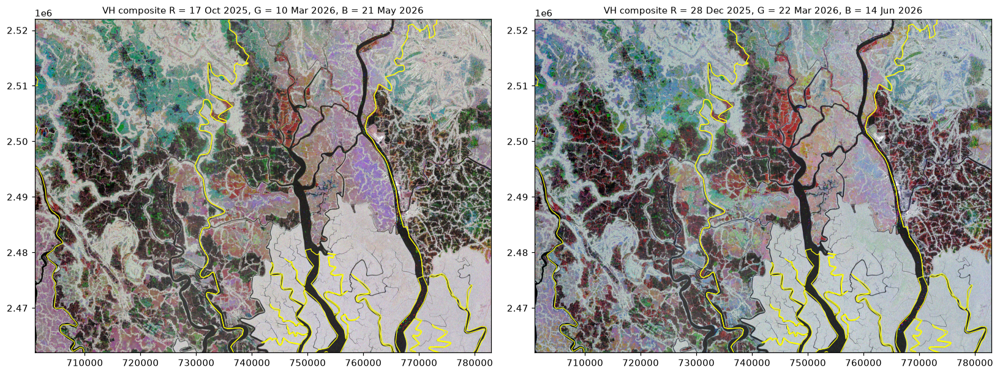

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5.8))
ext_w = [float(win.x.min()), float(win.x.max()), float(win.y.min()), float(win.y.max())]
for a, dates, ttl in [(ax[0], COMP_A, "R = 17 Oct 2025, G = 10 Mar 2026, B = 21 May 2026"),
                      (ax[1], ["2025-12-28", "2026-03-22", "2026-06-14"], "R = 28 Dec 2025, G = 22 Mar 2026, B = 14 Jun 2026")]:
    a.imshow(rgb_composite(vh_db, dates), extent=ext_w); a.set_title("VH composite " + ttl, fontsize=10); a.grid(False)
    dist_win.boundary.plot(ax=a, color="yellow", lw=0.8)
    a.set_xlim(ext_w[0], ext_w[1]); a.set_ylim(ext_w[2], ext_w[3])
plt.tight_layout(); plt.show()

**How to read the window composites.** In the right image (R = 28 Dec 2025, G = 22 Mar 2026, B = 14 Jun 2026), a gher that was drained in late December and full of water in March and June shows **red**. The dark-red block pattern covers most of the gher belt, with the dikes visible as a fine bright grid. Rivers are black on all dates, and trees and settlements are light grey.


## Separating rivers from ghers


Rivers and year-round ghers are both water in both seasons, so the water fractions alone cannot tell them apart. We use three properties of a river:

1. it **does not drain**: drain hump below 1.5 dB;
2. it has a **long water record**: JRC occurrence of at least 85 %, while many ghers were dug after 1984 or are dried every year;
3. it is **connected** to wide channels: we seed the mask with channel cores more than 100 m from the bank (JRC ≥ 95 %) and grow it through the connected candidate pixels (`scipy.ndimage.binary_propagation`).

Inside the **Sundarbans reserve forest**, where ghers are not permitted, every pixel that is water in the shrimp season is a tidal channel.


In [19]:
wfS = feat_stats.water_frac_shrimp.values; wfA = feat_stats.water_frac_aman.values; hump = feat_stats.drain_hump.values

def river_mask():
    # open river, estuary and tidal-channel water: year-round water, a long water record (JRC) and no drain hump,
    # grown from wide channel cores (more than 100 m from the bank) through connected candidate pixels
    yr = (wfS >= 0.8) & (wfA >= 0.8)
    cand = yr & (jrc >= 85) & (hump < 1.5)
    seeds = cand & (ndi.distance_transform_edt(yr) > 5) & (jrc >= 95)
    rivers = ndi.binary_propagation(seeds, mask=cand)
    # tidal channels inside the Sundarbans: no ghers are allowed in the reserve forest, so water enclosed by mangrove is channel
    forest = ndi.binary_fill_holes(ndi.binary_closing(wc_arr == 95, iterations=10))
    return rivers | (forest & (wfS >= 0.5))

river = river_mask()
yr_water = (wfS >= 0.8) & (wfA >= 0.8)
red_e = S2["early dry (15 Nov - 31 Dec 2025)"].B04.values
rows = {}
for name, m in [("river mask", river), ("other year-round water", yr_water & ~river)]:
    rows[name] = {"km²": m.sum() * 4e-4, "JRC occurrence (median %)": np.median(jrc[m]),
                  "drain hump (median dB)": np.median(hump[m]), "drained (hump >= 2 dB, %)": (hump[m] >= 2).mean() * 100,
                  "S2 red reflectance, early dry (median)": np.nanmedian(red_e[m])}
print(f"year-round water (VH < {WATER_DB:.0f} dB on at least 80 % of dates in both seasons): {yr_water.sum() * 4e-4:,.0f} km²")
pd.DataFrame(rows).T.round(3)

year-round water (VH < -18 dB on at least 80 % of dates in both seasons): 1,233 km²


,km²,JRC occurrence (median %),drain hump (median dB),"drained (hump >= 2 dB, %)","S2 red reflectance, early dry (median)"
river mask,226.304,97.0,0.432,0.184,0.111
other year-round water,1009.615,71.0,2.564,58.890,0.083


The two groups differ on every test, including one the mask does not use. River pixels have a median JRC occurrence of 97 %, almost no drain hump and turbid water (red reflectance 0.111). The other year-round water has a median JRC occurrence of 71 %, a median hump of 2.6 dB, 59 % of it drained in December–January, and clearer water (0.083). The Sentinel-2 turbidity was not used to build the mask, so the agreement is an independent sign that the mask separates rivers from ponds.

Narrow canals (*khals*) less than about 100 m wide and not connected to a seed stay in the gher classes; Section 18 discusses this.


## Rule-based gher mapping and pond-preparation dates


The rules use the VH dB series and the variables of Sections 9 and 10. Aman rice and dry-season crops are found with `sar.apps.rice_map`, which looks for a *flood minimum* followed by a *rise within a window*.

| Class | Rule (loose) | Strict version, for training labels |
|---|---|---|
| River, estuary, tidal channel | river mask (Section 10) | same |
| **Year-round gher** | $f_S\ge0.7$, $f_A\ge0.7$, no Aman rice | $f_S\ge0.9$, $f_A\ge0.9$, no Aman rice (loose), ≥ 100 m from the river mask |
| **Shrimp–rice rotation gher** | $f_S\ge0.7$ and Aman rice (`flood_db` −18, `rise_db` 4, 100 days, peak ≥ −16) | $f_S\ge0.9$ and Aman rice (−19, 6, 100 days, ≥ −15), ≥ 100 m from the river |
| Seasonal gher, no rice detected | $f_S\ge0.7$, $f_A<0.7$, no Aman rice | $f_S\ge0.9$, $f_A<0.7$, no Aman rice (loose), ≥ 100 m from the river |
| Aman rice (no gher) | Aman rice and $f_S<0.3$ | strict Aman rice and $f_S<0.1$ |
| Dry-season crop | `rice_map` on 4 Dec – 27 Apr (−18, 4, 120 days, ≥ −16) and $f_S<0.3$ | (−19, 6, 120 days, ≥ −15) and $f_S<0.1$ |
| Mangrove; trees and settlements | WorldCover 95; WorldCover 10 and 50, where $f_S<0.7$ | same |
| Other land | everything else (fallow, saline bare soil, grass, mixed pixels) | same |

Pixels that pass the loose rule of a class but not the strict one are *ambiguous* and are left out of training in Section 13. The strict "no rice" classes exclude anything the *loose* Aman rule calls rice, so a rotation gher with a weak rice signal cannot become a training pixel of another gher class.


In [20]:
RULES = {   # level -> thresholds
    "loose":  dict(gher_water=0.7, monsoon_water=0.7, aman=(-18, 4, 100, -16), dry=(-18, 4, 120, -16), dry_land=0.3),
    "strict": dict(gher_water=0.9, monsoon_water=0.9, aman=(-19, 6, 100, -15), dry=(-19, 6, 120, -15), dry_land=0.1,
                   river_buffer=5),
}
AMAN_SL, DRY_SL = ("2025-07-13", "2025-11-22"), ("2025-12-04", "2026-04-27")

def gher_rules(db, level="loose", loose=None):
    # loose: the loose result, passed for the strict level so that strict "no rice" and "dry" classes also
    # exclude everything the loose rules call rice or water
    r = RULES[level]
    out = {}
    for name, sl in [("aman", AMAN_SL), ("dry", DRY_SL)]:
        fl, rs, wd, pk = r[name]
        res = sarapps.rice_map(db.sel(time=slice(*sl)), db_input=True, flood_db=fl, rise_db=rs, window_days=wd, min_peak_db=pk)
        out[name] = res["rice"].values.astype(bool)
        out[name + "_date"] = res["transplanting_date"].values
    gher = wfS >= r["gher_water"]
    if "river_buffer" in r:
        gher &= ~ndi.binary_dilation(river, iterations=r["river_buffer"])   # strict: at least 100 m from open river water
    no_rice = ~out["aman"] if loose is None else ~loose["aman"]
    out["gher_rotation"] = gher & out["aman"]
    out["gher_yearround"] = gher & no_rice & (wfA >= r["monsoon_water"])
    out["gher_other"] = gher & no_rice & (wfA < RULES["loose"]["monsoon_water"])
    no_water = wfS < r["dry_land"]           # little or no water in the shrimp season
    out["aman_rice"] = out["aman"] & no_water
    out["dry_crop"] = out["dry"] & no_water
    return out

t0 = time.time()
loose = gher_rules(vh_db, "loose")
strict = gher_rules(vh_db, "strict", loose=loose)
print(f"rules done in {time.time() - t0:.0f} s")
keys = ["gher_yearround", "gher_rotation", "gher_other", "aman_rice", "dry_crop"]
pd.DataFrame({k: {"loose km²": loose[k].sum() * 4e-4, "strict km²": strict[k].sum() * 4e-4,
                  "loose % of window": loose[k].mean() * 100} for k in keys}).T.round(1)

rules done in 18 s


,loose km²,strict km²,loose % of window
gher_yearround,1285.9,863.2,26.1
gher_rotation,109.0,19.6,2.2
gher_other,102.9,57.1,2.1
aman_rice,415.2,130.6,8.4
dry_crop,396.8,63.3,8.1


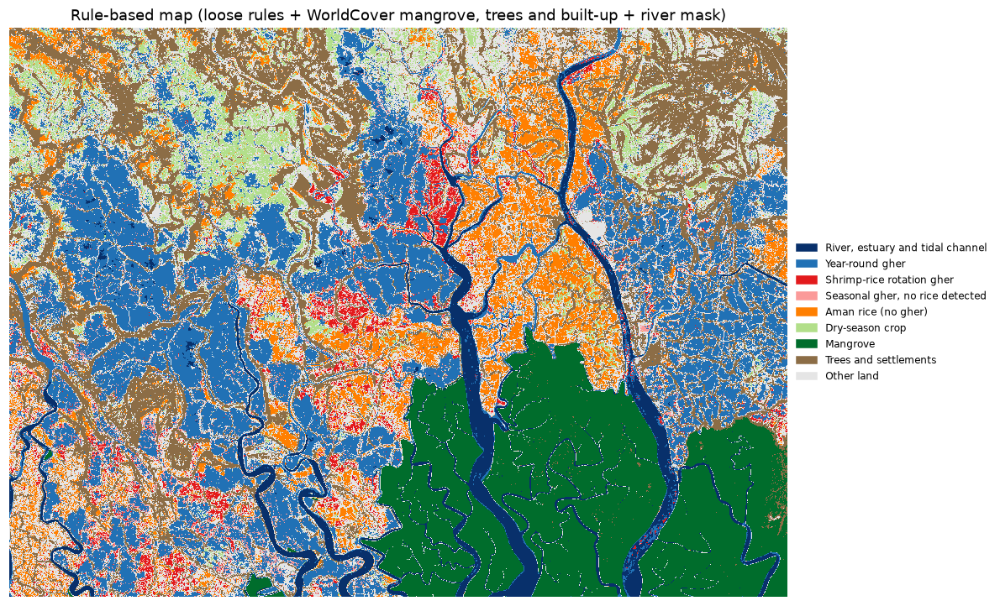

,class,km²,% of window
1,"River, estuary and tidal channel",226.3,4.6
2,Year-round gher,1063.1,21.6
3,Shrimp-rice rotation gher,107.6,2.2
4,"Seasonal gher, no rice detected",101.9,2.1
5,Aman rice (no gher),411.5,8.4
6,Dry-season crop,234.8,4.8
7,Mangrove,733.8,14.9
8,Trees and settlements,938.1,19.1
9,Other land,1102.9,22.4


In [21]:
CLASSES = {1: "River, estuary and tidal channel", 2: "Year-round gher", 3: "Shrimp-rice rotation gher", 4: "Seasonal gher, no rice detected",
           5: "Aman rice (no gher)", 6: "Dry-season crop", 7: "Mangrove", 8: "Trees and settlements", 9: "Other land"}
PALETTE = {1: "#08306b", 2: "#2171b5", 3: "#e31a1c", 4: "#fb9a99", 5: "#ff7f00", 6: "#b2df8a", 7: "#006d2c",
           8: "#8c6d46", 9: "#e5e5e5"}
GHER = [2, 3, 4]

def compose_classes(m):
    # later assignments overwrite earlier ones
    cls = np.full(wc_arr.shape, 9, "int16")
    cls[m["dry_crop"]] = 6
    cls[m["aman_rice"]] = 5
    cls[((wc_arr == 10) | (wc_arr == 50)) & (wfS < 0.7)] = 8     # WorldCover trees and built-up that are not under water
    cls[(wc_arr == 95) & (wfS < 0.7)] = 7                        # Sundarbans mangrove (WorldCover 95)
    cls[m["gher_other"]] = 4
    cls[m["gher_yearround"]] = 2
    cls[m["gher_rotation"]] = 3
    cls[river] = 1
    return cls

cls_rule = compose_classes(loose)
cls_strict = compose_classes(strict)

def show_classes(ax, arr, title):
    cmap = ListedColormap([PALETTE[k] for k in CLASSES]); norm = BoundaryNorm(np.arange(0.5, len(CLASSES) + 1.5), len(CLASSES))
    ax.imshow(arr, cmap=cmap, norm=norm, interpolation="nearest"); ax.set_title(title); ax.axis("off")

def class_legend(ax):
    ax.legend(handles=[Patch(color=PALETTE[k], label=v) for k, v in CLASSES.items()], loc="center left",
              bbox_to_anchor=(1, 0.5), fontsize=8, frameon=False)

fig, ax = plt.subplots(figsize=(11, 8))
show_classes(ax, cls_rule, "Rule-based map (loose rules + WorldCover mangrove, trees and built-up + river mask)"); class_legend(ax)
plt.show()
cnt = pd.Series(cls_rule.ravel()).value_counts().sort_index()
pd.DataFrame({"class": [CLASSES[k] for k in cnt.index], "km²": (cnt.values * 4e-4).round(1),
              "% of window": (cnt.values / cls_rule.size * 100).round(1)}, index=cnt.index)

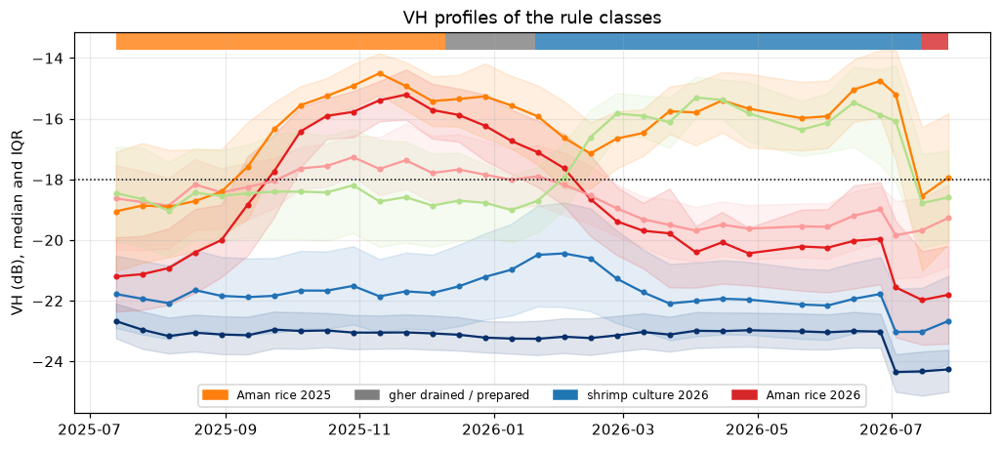

In [22]:
fig, ax = plt.subplots(figsize=(11, 4.6))
for k in [1, 2, 3, 4, 5, 6]:
    m = cls_rule == k
    q = np.nanpercentile(vh_db.values[:, m], [25, 50, 75], axis=1)
    ax.plot(vh_db.time, q[1], "-o", ms=3, color=PALETTE[k], label=CLASSES[k]); ax.fill_between(vh_db.time, q[0], q[2], color=PALETTE[k], alpha=0.12)
ax.axhline(WATER_DB, color="k", ls=":", lw=1); ax.set_ylabel("VH (dB), median and IQR")
ax.set_title("VH profiles of the rule classes"); ax.legend(fontsize=8, ncol=3, loc="lower left"); seasons_bar(ax)
plt.show()

**Reading the class profiles.**

- **Year-round gher (blue)** stays near −22 dB all year, with the drain hump in January (median −20.4 dB, upper quartile above −19 dB).
- **Shrimp–rice rotation gher (red)** is dark in July, rises to about −15.5 dB in October–November with the Aman canopy, falls when the gher is flooded in January and stays near −20 dB through the shrimp season. It is about 2 dB brighter than a year-round gher in that season: the water is shallower and part of the pixel is dike or rice stubble.
- **Seasonal gher, no rice detected (pink)** is a mixture: wet in the shrimp season, intermediate (about −18 dB) in the monsoon. Some of it is rotation ghers whose rice signal is too weak for the rule; some is fallow or grass.
- **Aman rice (orange)** has the rice rise but stays above the water threshold in the shrimp season. The **dry-season crop (light green)** rises from February to June.
- **Rivers (navy)** are flat near −23 dB.

All the water classes drop by about 1 dB on the three Sentinel-1D dates in July 2026, while the mangrove stable target does not (Section 7.1). This is a change in the water surface at the start of the monsoon, not a calibration step.


### Plausibility check against Sentinel-2 (no accuracy claim)

The Sentinel-2 composites were not used by the rules, so they give an independent check of what each class should look like: water in the late dry season and a green canopy at the end of the Aman season.


In [23]:
E, L = S2["early dry (15 Nov - 31 Dec 2025)"], S2["late dry (1 Feb - 15 Apr 2026)"]
s2_water_late = (L.mndwi > 0).values            # open water in the shrimp season (Feb - mid-Apr 2026)
s2_green_early = (E.ndvi > 0.3).values          # green canopy at the end of the Aman season (mid-Nov - Dec 2025)
rows = {}
for k, n in CLASSES.items():
    m = cls_rule == k
    rows[n] = {"km²": m.sum() * 4e-4, "S2 water, late dry (%)": s2_water_late[m].mean() * 100,
               "S2 green, early dry (%)": s2_green_early[m].mean() * 100,
               "WorldCover water (%)": (wc_arr[m] == 80).mean() * 100, "JRC occurrence (median %)": np.median(jrc[m])}
pd.DataFrame(rows).T.round(1)

,km²,"S2 water, late dry (%)","S2 green, early dry (%)",WorldCover water (%),JRC occurrence (median %)
"River, estuary and tidal channel",226.3,98.6,1.0,98.2,97.0
Year-round gher,1063.1,77.3,4.3,85.6,71.0
Shrimp-rice rotation gher,107.6,35.3,80.8,15.4,18.0
"Seasonal gher, no rice detected",101.9,42.3,42.6,39.5,31.0
Aman rice (no gher),411.5,4.9,87.2,3.0,0.0
Dry-season crop,234.8,2.9,33.5,9.7,9.0
Mangrove,733.8,1.0,98.8,0.0,0.0
Trees and settlements,938.1,0.9,95.1,0.0,0.0
Other land,1102.9,8.8,61.6,17.1,3.0


**Reading the check.**

- **Rivers** are water in Sentinel-2 almost everywhere (98.6 %).
- **Year-round ghers** are water in the late dry season on 77 % of their area and green at the end of the Aman season on only 4 %, as expected for ponds that hold water through the monsoon.
- **Rotation ghers** are green at the end of the Aman season on 81 % of their area (Aman rice 87 %). They are open water in Sentinel-2 on only 35 % in February–April: shallow, partly vegetated ponds, and dikes, give a positive MNDWI less often than deep water, even though the radar sees them as dark.
- **WorldCover** calls 86 % of the year-round ghers *permanent water* but only 15 % of the rotation ghers.

These are consistency checks against independent data, not a validation of the gher map.


### Pond preparation: drain and refill dates

For every year-round or seasonal gher pixel with a drain hump of at least 2 dB, the **drain date** is the date of the highest VH between 10 November 2025 and 15 April 2026, and the **refill date** is the first later date with VH below −18 dB. Both have the 12-day precision of the revisit. Rotation ghers are left out: their highest VH in this period is the rice canopy in November, so the method would date the rice, not the pond.


year-round and seasonal gher pixels with a drain hump of at least 2 dB: 682 km² (59 % of their area)
median drain date 2026-01-21, median refill date 2026-02-02, median dry period 12 days; 0 % of drained ghers not refilled by 15 Apr


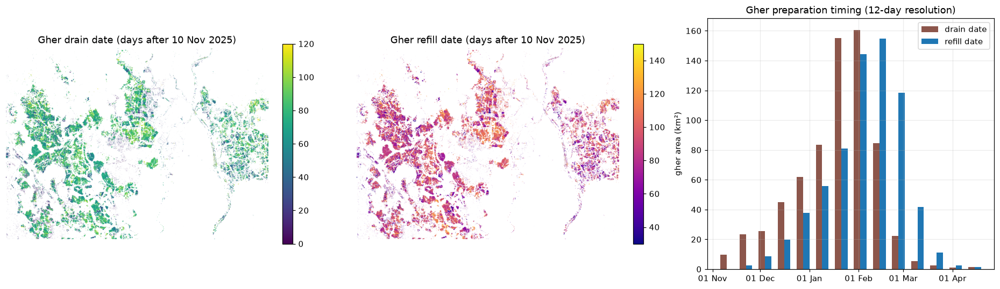

In [24]:
# drain date: the date of the highest VH between November and April (the dry pond floor);
# refill date: the first date after it at which VH is back below the water threshold (pond filled for stocking).
# Rotation ghers are left out: their highest VH in this period is the rice canopy in November, not a dry pond floor.
win_p = vh_db.sel(time=slice("2025-11-10", "2026-04-15"))
tv = win_p.time.values.astype("datetime64[D]")
a = win_p.values
i_max = a.argmax(0)
below = (a < WATER_DB) & (np.arange(len(tv))[:, None, None] > i_max[None])
i_fill = np.where(below.any(0), below.argmax(0), -1)
DATED = [2, 4]                                   # year-round and seasonal ghers
drained = np.isin(cls_rule, DATED) & (hump >= 2.0)
drain_date = np.where(drained, tv[i_max], np.datetime64("NaT"))
fill_date = np.where(drained & (i_fill >= 0), tv[np.clip(i_fill, 0, None)], np.datetime64("NaT"))
print(f"year-round and seasonal gher pixels with a drain hump of at least 2 dB: {drained.sum() * 4e-4:,.0f} km² "
      f"({drained.sum() / np.isin(cls_rule, DATED).sum() * 100:.0f} % of their area)")
ok = ~np.isnat(fill_date)
dur = (fill_date[ok] - drain_date[ok]).astype("timedelta64[D]").astype(int)
print(f"median drain date {pd.Series(drain_date[drained]).median().date()}, median refill date "
      f"{pd.Series(fill_date[ok]).median().date()}, median dry period {np.median(dur):.0f} days; "
      f"{(~ok[drained]).mean() * 100:.0f} % of drained ghers not refilled by 15 Apr")

ref = np.datetime64("2025-11-10")
fig, ax = plt.subplots(1, 3, figsize=(17, 5))
im0 = ax[0].imshow(np.where(np.isnat(drain_date), np.nan, (drain_date - ref).astype(float)), cmap="viridis", vmin=0, vmax=120)
ax[0].set_title("Gher drain date (days after 10 Nov 2025)")
im1 = ax[1].imshow(np.where(np.isnat(fill_date), np.nan, (fill_date - ref).astype(float)), cmap="plasma", vmin=30, vmax=150)
ax[1].set_title("Gher refill date (days after 10 Nov 2025)")
for a_, im in zip(ax[:2], [im0, im1]):
    a_.axis("off"); plt.colorbar(im, ax=a_, fraction=0.035)
dv = pd.Series(pd.to_datetime(drain_date[drained])).value_counts().sort_index()
fv = pd.Series(pd.to_datetime(fill_date[~np.isnat(fill_date)])).value_counts().sort_index()
ax[2].bar(dv.index - pd.Timedelta(days=2), dv.values * 4e-4, width=4, color="tab:brown", label="drain date")
ax[2].bar(fv.index + pd.Timedelta(days=2), fv.values * 4e-4, width=4, color="tab:blue", label="refill date")
ax[2].set_ylabel("gher area (km²)"); ax[2].legend(); ax[2].set_title("Gher preparation timing (12-day resolution)")
ax[2].xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
plt.tight_layout(); plt.show()

About 59 % of the year-round and seasonal gher area shows a clear drain hump. Draining peaks around **21 January 2026** and refilling about 12 days later, in early February, which matches the stocking of shrimp post-larvae in February. Ghers in the east of the window (Bagerhat) tend to be drained earlier, around late December, than those in Satkhira and Khulna. The rest of the gher area either did not dry long enough to be seen on a 12-day revisit, or stayed wet.


## Unsupervised classification of the time series


K-means (`ic.unsupervised_classify`) groups pixels by the shape of their VH series, with no labels and no rules. The clusters are only statistical groups; we name them afterwards from their mean profiles. This checks whether the temporal patterns that the rules describe exist in the data on their own.


k-means done in 9 s


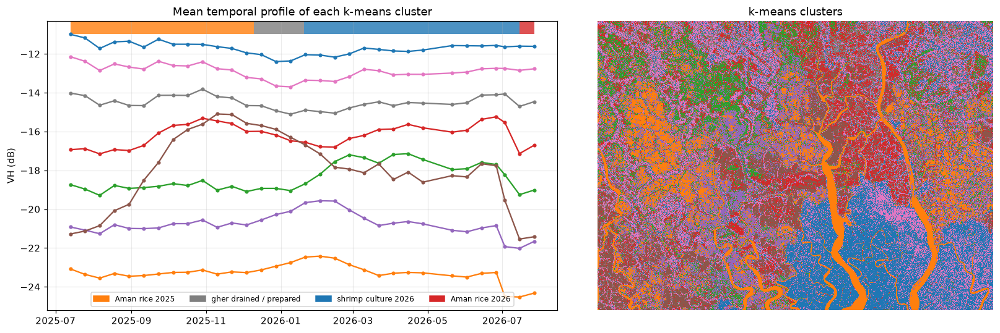

rule class,"River, estuary and tidal channel",Year-round gher,Shrimp-rice rotation gher,"Seasonal gher, no rice detected",Aman rice (no gher),Dry-season crop,Mangrove,Trees and settlements,Other land
cluster,,,,,,,,,
0,0.0,0.0,0.0,0.0,0.0,0.0,71.0,27.0,3.0
1,31.0,68.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
2,1.0,13.0,1.0,11.0,3.0,30.0,0.0,2.0,38.0
3,0.0,0.0,0.0,0.0,37.0,10.0,1.0,8.0,44.0
4,3.0,85.0,2.0,2.0,0.0,1.0,0.0,0.0,8.0
5,0.0,0.0,25.0,8.0,31.0,0.0,0.0,0.0,36.0
6,0.0,0.0,0.0,0.0,0.0,0.0,24.0,62.0,14.0
7,0.0,0.0,0.0,0.0,5.0,2.0,2.0,36.0,55.0


In [25]:
kfeat = xr.Dataset({f"vh_{i:02d}": vh_db.isel(time=i, drop=True) for i in range(T)})
K = 8
t0 = time.time()
km_map, km = ic.unsupervised_classify(kfeat, n_classes=K, method="minibatch_kmeans", sample=200_000, seed=SEED)
print(f"k-means done in {time.time() - t0:.0f} s")
cm_means = km.cluster_means_.to_numpy()
sizes = [(km_map.values == k).mean() * 100 for k in range(K)]

fig, ax = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [1.2, 1]})
cmap_k = plt.get_cmap("tab10")
for k in range(K):
    ax[0].plot(vh_db.time, cm_means[k], "-o", ms=3, color=cmap_k(k), label=f"cluster {k} ({sizes[k]:.1f} %)")
ax[0].set_ylabel("VH (dB)"); ax[0].set_title("Mean temporal profile of each k-means cluster"); ax[0].legend(fontsize=7, ncol=2, loc="lower left")
seasons_bar(ax[0])
ax[1].imshow(km_map.values, cmap=ListedColormap([cmap_k(k) for k in range(K)]), interpolation="nearest")
ax[1].set_title("k-means clusters"); ax[1].axis("off")
plt.tight_layout(); plt.show()

# which rule class dominates each cluster
ct = pd.crosstab(pd.Series(km_map.values.ravel(), name="cluster"),
                 pd.Series([CLASSES[c] for c in cls_rule.ravel()], name="rule class"), normalize="index").mul(100).round(0)
ct[[CLASSES[k] for k in CLASSES if CLASSES[k] in ct.columns]]

**Reading the clusters.** The table gives, for each cluster, the share of its pixels in each rule class. Two clusters are almost pure gher: one holds the year-round ghers and the other the ghers mixed with the rivers, because k-means sees them as the same dark profile. The mangrove and tree clusters are dominated by WorldCover's mangrove, tree and settlement classes. The Aman and rotation pixels share a cluster with a strong monsoon rise. The flat dark river profile and the drained-gher profile are both found without labels, so the structure the rules rely on is real. k-means knows nothing about the calendar, however, and its clusters do not follow the class definitions.


## Supervised classification with Random Forest: Sentinel-1 alone and with Sentinel-2


**Training labels.** Gher and rice classes come from the *strict* rules, rivers from the river mask, mangrove, trees and built-up from WorldCover, and **other land** from pixels that fail even the loose rules. Pixels that pass a loose rule but not the strict one are *ambiguous* and are excluded.

**Features.** Sentinel-1: the 32 VH and 32 VV dB values plus 14 temporal statistics (78 features). Sentinel-1 + Sentinel-2: the same plus the six bands and three indices of both dry-season composites (96 features).

**Split.** Pixels are sampled per class (at most 6 000 each) and assigned to train or test by **2 km spatial blocks** (`ic.spatial_block_split`); `ic.check_split_isolation` confirms that no block is shared. Both feature sets use exactly the same pixels and split.


In [26]:
rule_cls = [2, 3, 4, 5, 6]                       # classes defined by the SAR rules
amb = np.isin(cls_rule, rule_cls) & (cls_strict != cls_rule)
labels_map = np.where(amb, -1, cls_rule).astype("int16")
labels_map[np.isin(cls_strict, rule_cls)] = cls_strict[np.isin(cls_strict, rule_cls)]
print("training pool (pixels):", pd.Series(labels_map[labels_map > 0]).map(CLASSES).value_counts().to_dict())
print(f"ambiguous (loose but not strict) pixels left out: {(labels_map == -1).mean() * 100:.1f} % of the window")

# feature cubes as Datasets of 2-D bands (the format predict_map expects)
feat = xr.Dataset({f"vh_{i:02d}": vh_db.isel(time=i, drop=True) for i in range(T)})
feat.update({f"vv_{i:02d}": vv_db.isel(time=i, drop=True) for i in range(T)})
for k, v in feat_stats.data_vars.items():
    feat[k] = v
s1_names = list(feat.data_vars)
for tag, comp in [("s2e", S2["early dry (15 Nov - 31 Dec 2025)"]), ("s2l", S2["late dry (1 Feb - 15 Apr 2026)"])]:
    for b in S2_BANDS + ["ndvi", "mndwi", "ndwi"]:
        feat[f"{tag}_{b}"] = comp[b].astype("float32").drop_vars("spatial_ref", errors="ignore")
s12_names = list(feat.data_vars)
print(f"{len(s1_names)} Sentinel-1 features, {len(s12_names)} with the Sentinel-2 composites")

MAX_PER_CLASS = 6000
idx = []
for c in CLASSES:
    ii = np.flatnonzero(labels_map.ravel() == c)
    if ii.size:
        idx.append(rng.choice(ii, min(MAX_PER_CLASS, ii.size), replace=False))
idx = np.concatenate(idx)
rr, cc = np.unravel_index(idx, labels_map.shape)
y_all = labels_map[rr, cc]
coords = np.column_stack([feat.x.values[cc], feat.y.values[rr]])
X_all = pd.DataFrame(np.stack([feat[n].values[rr, cc] for n in s12_names], 1), columns=s12_names)

split = ic.spatial_block_split(coords, block_size=2000, test_size=0.3, seed=SEED, stratify=y_all)
blocks = ic.spatial_blocks(coords, 2000)
ic.check_split_isolation(train=blocks[split.train], test=blocks[split.test])
print(f"train {len(split.train):,} px / test {len(split.test):,} px; blocks shared: 0")
print(pd.DataFrame({"train": pd.Series(y_all[split.train]).map(CLASSES).value_counts(),
                    "test": pd.Series(y_all[split.test]).map(CLASSES).value_counts()}).fillna(0).astype(int))

training pool (pixels): {'Other land': 2757234, 'Trees and settlements': 2345257, 'Year-round gher': 2157914, 'Mangrove': 1834568, 'River, estuary and tidal channel': 565761, 'Aman rice (no gher)': 325450, 'Seasonal gher, no rice detected': 142780, 'Dry-season crop': 122177, 'Shrimp-rice rotation gher': 49095}
ambiguous (loose but not strict) pixels left out: 16.3 % of the window
78 Sentinel-1 features, 96 with the Sentinel-2 composites


train 38,078 px / test 15,922 px; blocks shared: 0
                                  train  test
Aman rice (no gher)                4273  1727
Dry-season crop                    3888  2112
Mangrove                           4370  1630
Other land                         4170  1830
River, estuary and tidal channel   4279  1721
Seasonal gher, no rice detected    4265  1735
Shrimp-rice rotation gher          4460  1540
Trees and settlements              4168  1832
Year-round gher                    4205  1795


In [27]:
RF, REP, CV = {}, {}, {}
for name, cols in [("S1", s1_names), ("S1 + S2", s12_names)]:
    t0 = time.time()
    RF[name], CV[name] = ic.train_pixel_classifier(X_all.iloc[split.train][cols], y_all[split.train], model="rf",
                                                   coords=coords[split.train], block_size=2000, n_splits=4,
                                                   n_estimators=200, n_jobs=-1, seed=SEED)
    pred_te = RF[name].predict(X_all.iloc[split.test][cols])
    REP[name] = ic.classification_report(y_all[split.test], pred_te, labels=list(CLASSES), class_names=CLASSES, n_boot=200)
    cvm = CV[name][["accuracy", "macro_f1", "kappa"]].agg(["mean", "std"])
    print(f"{name:8s} trained in {time.time() - t0:.0f} s | spatial 4-fold CV OA {cvm.loc['mean', 'accuracy']:.3f} ± {cvm.loc['std', 'accuracy']:.3f} | "
          f"held-out blocks: OA {REP[name]['overall_accuracy']:.3f}, kappa {REP[name]['kappa']:.3f}, macro-F1 {REP[name]['macro_f1']:.3f}")
pd.DataFrame({f"{n} F1": REP[n]["per_class"]["f1"] for n in REP} |
             {"S1 + S2 F1 95% CI": REP["S1 + S2"]["per_class"][["f1_ci_low", "f1_ci_high"]].round(3).astype(str).agg(" - ".join, axis=1)}).round(3)

S1       trained in 14 s | spatial 4-fold CV OA 0.909 ± 0.008 | held-out blocks: OA 0.906, kappa 0.894, macro-F1 0.906


S1 + S2  trained in 16 s | spatial 4-fold CV OA 0.933 ± 0.008 | held-out blocks: OA 0.930, kappa 0.922, macro-F1 0.931


,S1 F1,S1 + S2 F1,S1 + S2 F1 95% CI
"River, estuary and tidal channel",0.934,0.951,0.944 - 0.958
Year-round gher,0.940,0.958,0.951 - 0.965
Shrimp-rice rotation gher,0.946,0.946,0.936 - 0.956
"Seasonal gher, no rice detected",0.946,0.947,0.939 - 0.955
Aman rice (no gher),0.943,0.946,0.938 - 0.953
Dry-season crop,0.951,0.955,0.948 - 0.961
Mangrove,0.897,0.971,0.965 - 0.977
Trees and settlements,0.765,0.851,0.837 - 0.862
Other land,0.833,0.854,0.843 - 0.866


**Sentinel-1 alone vs with Sentinel-2.** The gher classes are recognised equally well from the radar series alone (F1 0.93–0.96): the pond calendar *is* the signal. The optical composites add most to the **land** classes: mangrove (F1 0.90 → 0.97) and trees and settlements (0.77 → 0.85), which VH alone cannot separate. Overall agreement on the held-out blocks rises by about 2 points. The S1 + S2 model is used for the map.


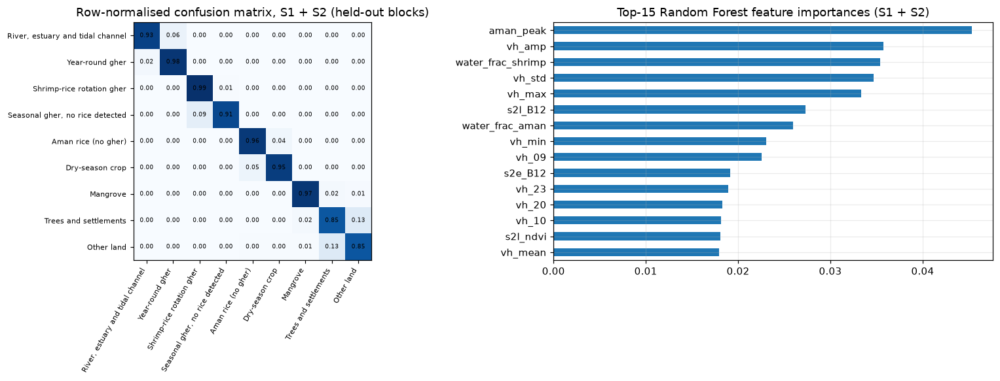

In [28]:
rf, rep_rf, feat_names = RF["S1 + S2"], REP["S1 + S2"], s12_names
cmx = rep_rf["confusion_matrix"]
fig, ax = plt.subplots(1, 2, figsize=(15, 5.4), gridspec_kw={"width_ratios": [1.1, 1]})
cmn = cmx.div(cmx.sum(1).replace(0, np.nan), axis=0)
ax[0].imshow(cmn.values, cmap="Blues", vmin=0, vmax=1)
ax[0].set_xticks(range(len(cmx))); ax[0].set_xticklabels(cmx.columns, rotation=60, ha="right", fontsize=7)
ax[0].set_yticks(range(len(cmx))); ax[0].set_yticklabels(cmx.index, fontsize=7)
for i in range(len(cmx)):
    for j in range(len(cmx)):
        ax[0].text(j, i, f"{cmn.values[i, j]:.2f}" if np.isfinite(cmn.values[i, j]) else "", ha="center", va="center", fontsize=6)
ax[0].set_title("Row-normalised confusion matrix, S1 + S2 (held-out blocks)"); ax[0].grid(False)
imp = pd.Series(rf.model.feature_importances_, index=feat_names).sort_values(ascending=False).head(15)
imp.iloc[::-1].plot.barh(ax=ax[1], color="tab:blue"); ax[1].set_title("Top-15 Random Forest feature importances (S1 + S2)")
plt.tight_layout(); plt.show()

RF map of 12.3 M pixels in 57 s


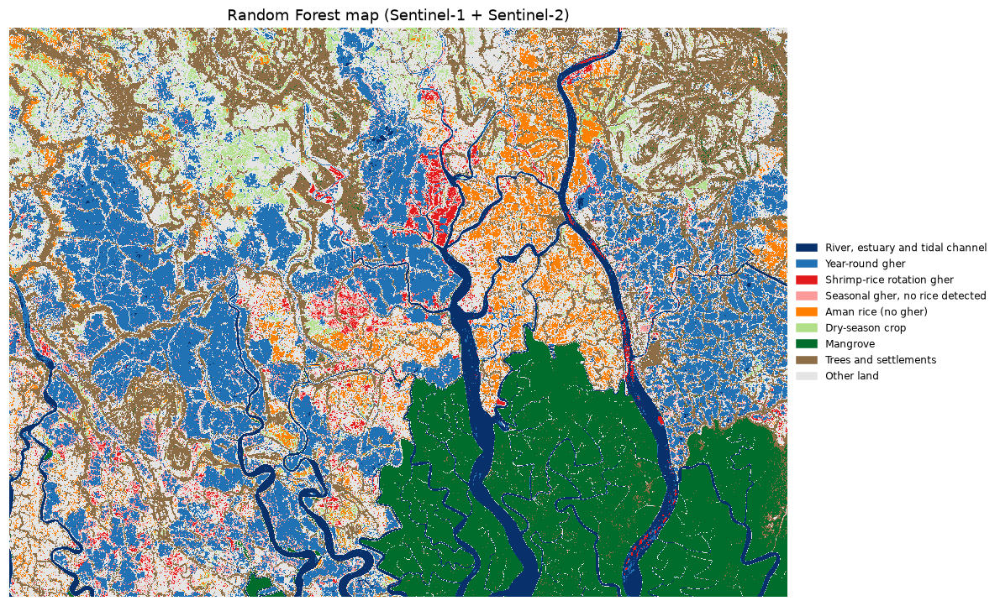

In [29]:
t0 = time.time()
cls_rf = ic.predict_map(rf, feat[feat_names], chunk_rows=256).values.astype("int16")
print(f"RF map of {cls_rf.size / 1e6:.1f} M pixels in {time.time() - t0:.0f} s")
fig, ax = plt.subplots(figsize=(11, 8))
show_classes(ax, cls_rf, "Random Forest map (Sentinel-1 + Sentinel-2)"); class_legend(ax); plt.show()

## Temporal deep learning with a TempCNN


`ic.build_temporal_model("tempcnn")` builds a 1-D CNN over the 32-date sequence of VH and VV (2 channels, in dB). It is trained on the **same pixels and the same spatial split** as the Random Forest, so the held-out scores are comparable. Inputs are standardised with training-set statistics and the loss is class-weighted cross-entropy. A GPU is used when available.


device: cuda


trained 25 epochs in 5 s


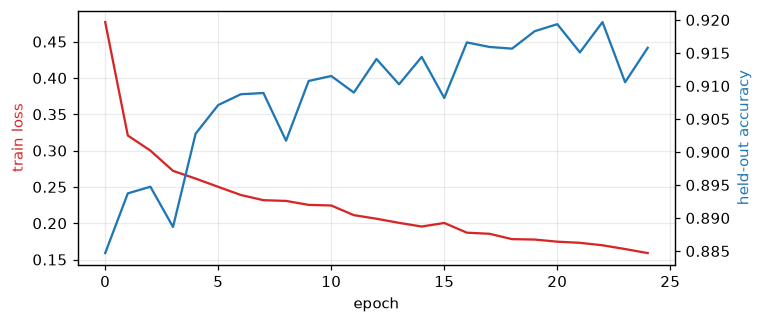

In [30]:
import torch
dev = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", dev)

def seq_array(rows, cols):
    return np.stack([vh_db.values[:, rows, cols].T, vv_db.values[:, rows, cols].T], -1).astype("float32")  # (N, T, 2)

Xs = seq_array(rr, cc)
mu, sd = Xs[split.train].mean((0, 1)), Xs[split.train].std((0, 1))
code_to_idx = {c: i for i, c in enumerate(CLASSES)}
yi = np.array([code_to_idx[v] for v in y_all])
torch.manual_seed(SEED)
net = ic.build_temporal_model("tempcnn", in_channels=2, num_classes=len(CLASSES), n_timesteps=T).to(dev)
w = torch.tensor(1.0 / np.bincount(yi[split.train], minlength=len(CLASSES)).clip(1), dtype=torch.float32)
w = (w / w.sum() * len(CLASSES)).to(dev)
opt = torch.optim.AdamW(net.parameters(), lr=2e-3, weight_decay=1e-4)
lossf = torch.nn.CrossEntropyLoss(weight=w)
Xtr = torch.tensor((Xs[split.train] - mu) / sd); ytr = torch.tensor(yi[split.train])
Xte = torch.tensor((Xs[split.test] - mu) / sd); yte = yi[split.test]

EPOCHS, BS = 25, 512
hist = []
t0 = time.time()
for ep in range(EPOCHS):
    net.train(); perm = torch.randperm(len(Xtr)); tot = 0
    for i in range(0, len(perm), BS):
        b = perm[i:i + BS]
        opt.zero_grad(); loss = lossf(net(Xtr[b].to(dev)), ytr[b].to(dev)); loss.backward(); opt.step(); tot += loss.item() * len(b)
    net.eval()
    with torch.no_grad():
        pt = torch.cat([net(Xte[i:i + 4096].to(dev)).argmax(1).cpu() for i in range(0, len(Xte), 4096)]).numpy()
    hist.append((tot / len(Xtr), (pt == yte).mean()))
print(f"trained {EPOCHS} epochs in {time.time() - t0:.0f} s")
h = pd.DataFrame(hist, columns=["train_loss", "test_acc"])
fig, ax = plt.subplots(figsize=(7, 3)); h.train_loss.plot(ax=ax, color="tab:red"); ax.set_ylabel("train loss", color="tab:red")
ax2 = ax.twinx(); h.test_acc.plot(ax=ax2, color="tab:blue"); ax2.set_ylabel("held-out accuracy", color="tab:blue"); ax2.grid(False)
ax.set_xlabel("epoch"); plt.show()

TempCNN held-out blocks: OA 0.916, kappa 0.905, macro-F1 0.916

Per-class F1 on the same held-out blocks:
                                  RF S1 F1  RF S1 + S2 F1  TempCNN (S1) F1
River, estuary and tidal channel     0.934          0.951            0.947
Year-round gher                      0.940          0.958            0.947
Shrimp-rice rotation gher            0.946          0.946            0.955
Seasonal gher, no rice detected      0.946          0.947            0.954
Aman rice (no gher)                  0.943          0.946            0.951
Dry-season crop                      0.951          0.955            0.962
Mangrove                             0.897          0.971            0.923
Trees and settlements                0.765          0.851            0.790
Other land                           0.833          0.854            0.811


TempCNN map in 13 s


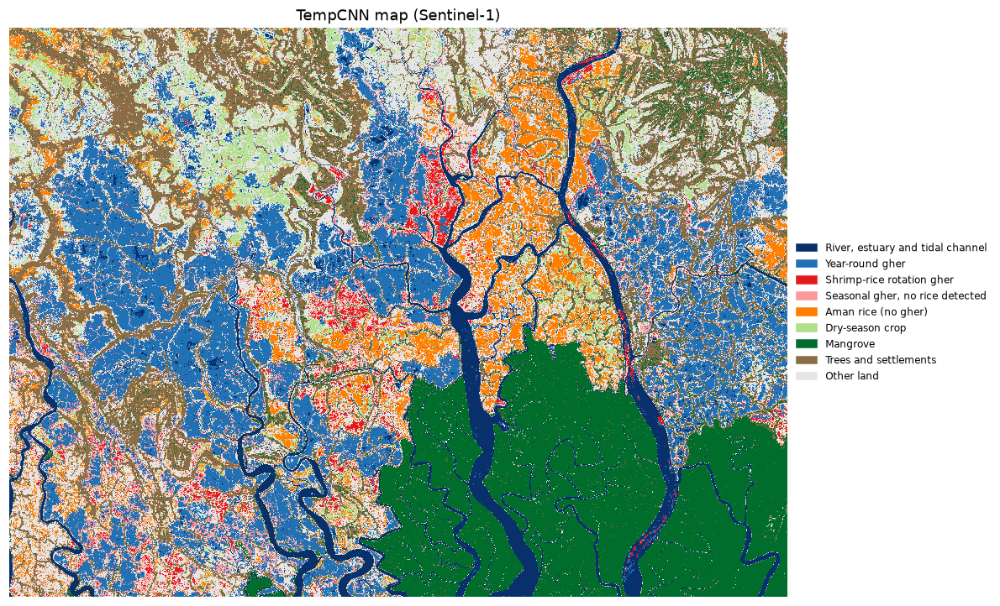

In [31]:
idx_to_code = {i: c for c, i in code_to_idx.items()}
pred_cnn = np.array([idx_to_code[i] for i in pt])
rep_cnn = ic.classification_report(y_all[split.test], pred_cnn, labels=list(CLASSES), class_names=CLASSES, n_boot=200)
print(f"TempCNN held-out blocks: OA {rep_cnn['overall_accuracy']:.3f}, kappa {rep_cnn['kappa']:.3f}, macro-F1 {rep_cnn['macro_f1']:.3f}")
cmp_ = pd.DataFrame({"RF S1 F1": REP["S1"]["per_class"]["f1"], "RF S1 + S2 F1": REP["S1 + S2"]["per_class"]["f1"],
                     "TempCNN (S1) F1": rep_cnn["per_class"]["f1"]})
print("\nPer-class F1 on the same held-out blocks:"); print(cmp_.round(3))

t0 = time.time()
H, W_ = wc_arr.shape
pred_full = np.empty(H * W_, "int16")
vh_flat = vh_db.values.reshape(T, -1); vv_flat = vv_db.values.reshape(T, -1)
lut = np.array([idx_to_code[j] for j in range(len(CLASSES))], "int16")
net.eval()
with torch.no_grad():
    for i in range(0, H * W_, 200_000):
        xb = np.stack([vh_flat[:, i:i + 200_000].T, vv_flat[:, i:i + 200_000].T], -1)
        xb = torch.tensor((xb - mu) / sd, dtype=torch.float32).to(dev)
        pred_full[i:i + 200_000] = lut[net(xb).argmax(1).cpu().numpy()]
cls_cnn = pred_full.reshape(H, W_)
print(f"TempCNN map in {time.time() - t0:.0f} s")
fig, ax = plt.subplots(figsize=(11, 8)); show_classes(ax, cls_cnn, "TempCNN map (Sentinel-1)"); class_legend(ax); plt.show()

The TempCNN uses only the radar sequence. It is slightly ahead of the Sentinel-1 Random Forest overall (OA 0.916 vs 0.906) and better on the rotation and seasonal ghers, whose identity lies in the *shape* of the series (a rise followed by a dip). Like the Sentinel-1 Random Forest, it is weaker than the S1 + S2 model on mangrove versus trees.


## Comparing the maps, cleaning and vectorising


Area per class (km²)
                                  Rules  Random Forest (S1 + S2)  TempCNN (S1)
River, estuary and tidal channel    226                      273           317
Year-round gher                    1063                      936           903
Shrimp-rice rotation gher           108                       66            83
Seasonal gher, no rice detected     102                      155           169
Aman rice (no gher)                 412                      234           299
Dry-season crop                     235                      148           185
Mangrove                            734                      741           847
Trees and settlements               938                      932           951
Other land                         1103                     1435          1166
All gher classes                   1273                     1157          1155

Pixel agreement between maps (%)
                         Rules  Random Forest (S1 + S2)  TempCNN (S1)
Rules 


Agreement on gher vs not gher (%)
                         Rules  Random Forest (S1 + S2)  TempCNN (S1)
Rules                    100.0                     97.1          96.7
Random Forest (S1 + S2)   97.1                    100.0          97.2
TempCNN (S1)              96.7                     97.2         100.0


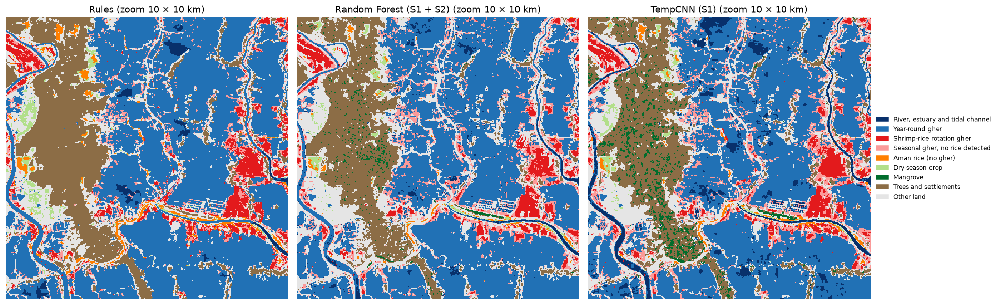

In [32]:
maps = {"Rules": cls_rule, "Random Forest (S1 + S2)": cls_rf, "TempCNN (S1)": cls_cnn}
rows = {}
for name, m in maps.items():
    cnt = pd.Series(m.ravel()).value_counts()
    rows[name] = {CLASSES[k]: cnt.get(k, 0) * 4e-4 for k in CLASSES}
area_cmp = pd.DataFrame(rows).round(0).astype(int)
area_cmp.loc["All gher classes"] = area_cmp.loc[[CLASSES[k] for k in GHER]].sum()
print("Area per class (km²)"); print(area_cmp)
agree = pd.DataFrame({a: {b: (maps[a] == maps[b]).mean() * 100 for b in maps} for a in maps}).round(1)
print("\nPixel agreement between maps (%)"); print(agree)
gher_agree = pd.DataFrame({a: {b: ((np.isin(maps[a], GHER)) == np.isin(maps[b], GHER)).mean() * 100 for b in maps} for a in maps}).round(1)
print("\nAgreement on gher vs not gher (%)"); print(gher_agree)

fig, ax = plt.subplots(1, 3, figsize=(18, 6.2))
rect = (slice(700, 1200), slice(1700, 2200))
for a, (name, m) in zip(ax, maps.items()):
    show_classes(a, m[rect], f"{name} (zoom 10 × 10 km)")
class_legend(ax[2]); plt.tight_layout(); plt.show()

The three maps agree on **gher vs not gher** for about 97 % of pixels, and on the total gher area to within about 10 % (rules 1,273 km², Random Forest 1,157 km², TempCNN 1,155 km²). They disagree more on the split between gher types and on the land classes (overall pixel agreement 81–86 %). The classifiers move part of the loose-rule year-round gher at river banks into the river class, and part of the loose Aman rice into other land. This is the expected effect of training on strict labels.

### Cleaning and vectorising

We take the **Random Forest (S1 + S2)** map and apply two constraints that the pixel classifiers cannot know:

- mangrove outside the Sundarbans reserve is homestead tree cover;
- there are no ghers or fields inside the reserve.

Then we remove gher and crop patches smaller than 25 pixels (1 ha), fill holes of the same size with `ic.clean_mask`, label the connected patches of each gher class, and convert them to polygons with `ic.polygonize` (patches of 1 ha or more). A polygon is a **patch of connected gher pixels of one type**, not a single gher: neighbouring ponds separated by dikes narrower than a 20 m pixel merge into one patch.


In [33]:
tmpl = vh_db.isel(time=0, drop=True)
forest = ndi.binary_fill_holes(ndi.binary_closing(wc_arr == 95, iterations=10))   # Sundarbans reserve forest (as in Section 10)
clean = cls_rf.copy()
clean[(clean == 7) & ~forest] = 8                          # mangrove outside the reserve: homestead trees
clean[forest & np.isin(clean, GHER + [5, 6])] = 1          # no ghers or fields inside the reserve: tidal water
for c in GHER + [5, 6]:
    m = clean == c
    keep = ic.clean_mask(m, min_size=25, hole_size=25, opening=0).astype(bool)
    clean[m & ~keep] = 9
clean_da = tmpl.copy(data=clean.astype("int32")).rename("class")
changed = (cls_rf != clean).sum()
print(f"pixels relabelled by clean-up: {changed:,} ({changed / clean.size * 100:.2f} %)")

t0 = time.time()
inst = np.zeros(clean.shape, "int32")                     # one id per connected patch of one gher class
n_inst = 0
for c in GHER:
    lab, n = ndi.label(clean == c)
    inst[lab > 0] = lab[lab > 0] + n_inst
    n_inst += n
inst_da = tmpl.copy(data=inst).rename("instance")
polys = ic.polygonize(inst_da, class_map=clean_da, class_names=CLASSES, min_area=10_000, simplify=10)
polys = polys.set_crs(CRS, allow_override=True)
print(f"{n_inst:,} connected gher patches, {len(polys):,} polygons of at least 1 ha in {time.time() - t0:.0f} s")
polys.groupby("class_name").agg(n=("id", "size"), median_ha=("area", lambda a: np.median(a) / 1e4),
                                largest_ha=("area", lambda a: a.max() / 1e4), total_km2=("area", lambda a: a.sum() / 1e6)).round(1)

pixels relabelled by clean-up: 631,520 (5.13 %)


6,199 connected gher patches, 6,132 polygons of at least 1 ha in 29 s


,n,median_ha,largest_ha,total_km2
class_name,,,,
"Seasonal gher, no rice detected",2309,1.8,94.0,67.4
Shrimp-rice rotation gher,942,2.2,169.3,50.1
Year-round gher,2881,2.5,4056.1,886.6


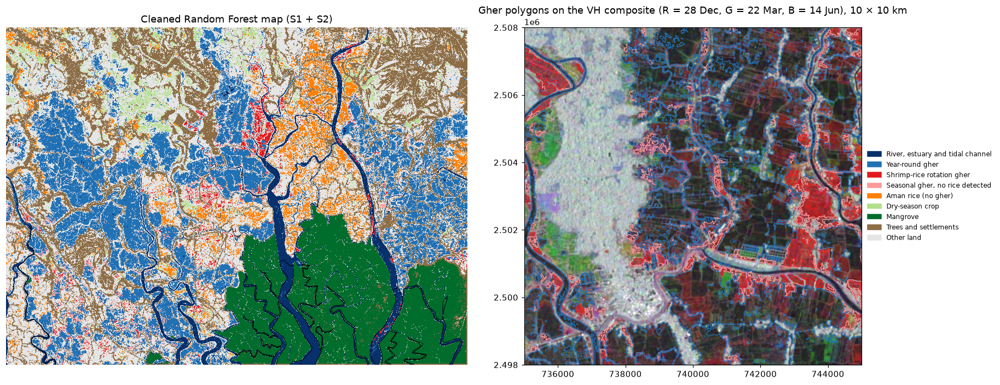

In [34]:
fig, ax = plt.subplots(1, 2, figsize=(17, 6.5), gridspec_kw={"width_ratios": [1.25, 1]})
show_classes(ax[0], clean, "Cleaned Random Forest map (S1 + S2)")
dist_mask = rfeat.rasterize([(g, 1) for g in districts.geometry], out_shape=clean.shape, transform=win_gb.affine, fill=0)
ax[0].contour(dist_mask, levels=[0.5], colors="k", linewidths=0.6)
zoom = (slice(700, 1200), slice(1700, 2200))
x0z, y0z = win_gb.affine * (zoom[1].start, zoom[0].stop)
x1z, y1z = win_gb.affine * (zoom[1].stop, zoom[0].start)
ax[1].imshow(rgb_composite(vh_db, ["2025-12-28", "2026-03-22", "2026-06-14"]), extent=[float(win.x.min()), float(win.x.max()), float(win.y.min()), float(win.y.max())])
polys.boundary.plot(ax=ax[1], color=[PALETTE[c] for c in polys["class"]], lw=0.8)
ax[1].set_xlim(x0z, x1z); ax[1].set_ylim(y0z, y1z); ax[1].grid(False)
ax[1].set_title("Gher polygons on the VH composite (R = 28 Dec, G = 22 Mar, B = 14 Jun), 10 × 10 km")
class_legend(ax[1]); plt.tight_layout(); plt.show()

## Area and timing statistics by district


Areas are counted from the cleaned Random Forest map (each pixel is 20 × 20 m = 0.04 ha), for the part of each district inside the window. The gher share is given relative to the land outside rivers and the reserve forest. **These are map areas, not area estimates**: without a probability sample of reference points we cannot apply the Olofsson et al. (2014) estimator to correct them for classification error, and we do not report confidence intervals.


In [35]:
dist_ids = {n: i + 1 for i, n in enumerate(dist_win["Name"])}
dist_raster = rfeat.rasterize([(g, dist_ids[n]) for g, n in zip(dist_win.geometry, dist_win["Name"])],
                              out_shape=clean.shape, transform=win_gb.affine, fill=0, dtype="int16")
rows = []
for n, i in dist_ids.items():
    m = dist_raster == i
    land = m & ~np.isin(clean, [1, 7])                    # without open water and the reserve forest
    r = {"district": n, "in window km²": m.sum() * 4e-4, "land outside forest km²": land.sum() * 4e-4}
    for c in GHER + [5]:
        r[CLASSES[c]] = ((clean == c) & m).sum() * 4e-4
    r["All ghers km²"] = sum(r[CLASSES[c]] for c in GHER)
    r["ghers % of land"] = r["All ghers km²"] / r["land outside forest km²"] * 100
    rows.append(r)
stats = pd.DataFrame(rows).set_index("district").round(1)
stats

,in window km²,land outside forest km²,Year-round gher,Shrimp-rice rotation gher,"Seasonal gher, no rice detected",Aman rice (no gher),All ghers km²,ghers % of land
district,,,,,,,,
Bagerhat,966.4,754.3,198.0,3.1,5.6,10.1,206.7,27.4
Khulna,1907.8,1274.6,198.2,34.7,25.0,143.3,257.8,20.2
Satkhira,1824.5,1776.8,482.0,10.6,35.4,42.4,527.9,29.7


In [36]:
rows = []
for n, i in dist_ids.items():
    m = (dist_raster == i) & np.isin(clean, DATED) & ~np.isnat(drain_date)
    dd = pd.Series(pd.to_datetime(drain_date[m])); fd = pd.Series(pd.to_datetime(fill_date[m]))
    rows.append({"district": n, "drained gher km²": m.sum() * 4e-4,
                 "drained share of year-round and seasonal ghers (%)": m.sum() / max(((dist_raster == i) & np.isin(clean, DATED)).sum(), 1) * 100,
                 "median drain date": dd.median().date(), "median refill date": fd.median().date(),
                 "refilled by 2 Feb (%)": float((fd <= pd.Timestamp("2026-02-02")).mean() * 100)})
pd.DataFrame(rows).set_index("district").round(1)

,drained gher km²,drained share of year-round and seasonal ghers (%),median drain date,median refill date,refilled by 2 Feb (%)
district,,,,,
Bagerhat,110.4,54.3,2026-01-21,2026-02-02,59.0
Khulna,138.9,62.2,2026-01-21,2026-02-14,40.4
Satkhira,348.8,67.4,2026-01-21,2026-02-02,53.4


**Satkhira** has the largest gher area in the window (about 530 km², 30 % of its land outside the forest), almost all of it year-round. **Bagerhat** (only its western part is in the window) has a similar share but a smaller area. **Khulna** has the smallest share (20 %) but the most **shrimp–rice rotation** ghers and by far the most Aman rice outside ghers: the Dumuria–Batiaghata–Paikgachha belt lies at the fresher, northern end of the salinity gradient, where rice can still be grown in the monsoon. Draining peaks on 21 January in all three districts; Khulna's ghers are refilled about 12 days later than those of Satkhira and Bagerhat.


## Writing the outputs


In [37]:
colormap = {k: tuple(int(PALETTE[k][i:i + 2], 16) for i in (1, 3, 5)) for k in CLASSES}
meta = {"source": f"Sentinel-1 RTC (Planetary Computer), relative orbit {ORBIT}; Sentinel-2 L2A dry-season medians",
        "period": f"{str(times[0])[:10]} to {str(times[-1])[:10]}", "dates": str(T),
        "note": "no field reference data; gher and rice classes are rule-derived"}
written = []
for name, arr in [("gher_rules", cls_rule), ("gher_random_forest", clean), ("gher_tempcnn", cls_cnn)]:
    da = tmpl.copy(data=arr.astype("int32")).rio.write_crs(CRS)
    written.append(ic.write_class_map(da, OUT / f"{name}_20m.tif", class_names=CLASSES, colormap=colormap, metadata=meta))

def date_tif(path, dates, ref):
    a = np.where(np.isnat(dates), np.nan, (dates - np.datetime64(ref)).astype(float)).astype("float32")
    da = tmpl.copy(data=a).rio.write_crs(CRS); da.attrs = {"description": f"days since {ref}"}
    da.rio.to_raster(path, compress="deflate"); written.append(Path(path))
date_tif(OUT / "gher_drain_date_days_since_2025-11-10.tif", drain_date, "2025-11-10")
date_tif(OUT / "gher_refill_date_days_since_2025-11-10.tif", fill_date, "2025-11-10")

polys.to_file(OUT / "gher_patches.gpkg", layer="gher", driver="GPKG"); written.append(OUT / "gher_patches.gpkg")
stats.to_csv(OUT / "gher_area_by_district.csv"); written.append(OUT / "gher_area_by_district.csv")
inv.to_csv(OUT / "sentinel1_inventory.csv"); written.append(OUT / "sentinel1_inventory.csv")
pd.DataFrame({"RF S1": REP["S1"]["per_class"]["f1"], "RF S1 + S2": REP["S1 + S2"]["per_class"]["f1"],
              "TempCNN": rep_cnn["per_class"]["f1"]}).to_csv(OUT / "heldout_f1.csv"); written.append(OUT / "heldout_f1.csv")
for p in written:
    print(f"{p.name:52s} {p.stat().st_size / 1e6:8.2f} MB")

gher_rules_20m.tif                                       1.84 MB
gher_random_forest_20m.tif                               1.57 MB
gher_tempcnn_20m.tif                                     2.06 MB
gher_drain_date_days_since_2025-11-10.tif                1.31 MB
gher_refill_date_days_since_2025-11-10.tif               1.37 MB
gher_patches.gpkg                                       10.74 MB
gher_area_by_district.csv                                0.00 MB
sentinel1_inventory.csv                                  0.00 MB
heldout_f1.csv                                           0.00 MB


## Interpretation, caveats and recommended recipe


**What the measured numbers say** (gher window, 4,920 km², 20 m, 32 dates from 13 July 2025 to 27 July 2026, VH/VV after multi-temporal Lee filtering, two Sentinel-2 dry-season composites):

* **Ghers dominate the land between the rivers.** The rules map about 1,270 km² of ghers (26 % of the window); the Random Forest and the TempCNN map about 1,155 km². By district, ghers cover 30 % of the land of Satkhira, 27 % of west Bagerhat and 20 % of Khulna inside the window. WorldCover 2021 labels most of this area *permanent water*, which hides the aquaculture.
* **Most ghers hold water all year.** Year-round ghers are 78–84 % of the gher area, depending on the map. **Shrimp–rice rotation** ghers, with a clear Aman canopy in the radar and in Sentinel-2 (81 % green in November–December), are only about 110 km² in the rule map (65–85 km² in the classifier maps), concentrated in Khulna (Dumuria–Paikgachha). A further 100–170 km² of seasonal ghers show water in the shrimp season but no detectable rice.
* **The pond calendar is visible.** 59 % of the year-round and seasonal gher area shows a drain hump; draining peaks around 21 January 2026 and refilling around 2–14 February, a median dry period of 12 days, matching the February stocking of shrimp post-larvae.
* **Rivers can be separated from ponds.** The river mask (226 km²) has a median JRC occurrence of 97 %, almost no drain hump and turbid water in Sentinel-2. The remaining year-round water (1,010 km²) has a JRC occurrence of 71 %, 59 % of it was drained, and its water is clearer.
* **Supervised scores measure reproduction of rule-derived labels, not accuracy.** On spatially held-out 2 km blocks, the Random Forest reaches OA 0.906 with Sentinel-1 alone and 0.930 with Sentinel-2 (kappa 0.922, macro-F1 0.931); the TempCNN reaches 0.916. Sentinel-2 adds most to mangrove and trees, not to the gher classes. The three maps agree on gher vs not gher on about 97 % of pixels.
* **Polygons are connected patches, not ghers.** 6,132 patches of at least 1 ha were produced (median 1.8–2.5 ha), but adjacent ponds merge where dikes are narrower than a pixel; the largest year-round patch is about 4,000 ha.

**Caveats**

* **No field reference data were used.** Every gher and rice class is defined by thresholds on the SAR series. There is no accuracy statement and no area estimate with confidence intervals for any map.
* **Shrimp vs other aquaculture.** The radar sees a managed pond, not what is in it. Year-round ghers include freshwater prawn (*golda*) and fish ponds, especially in Bagerhat, as well as brackish shrimp ghers. The class names describe the water regime, not the species.
* **Narrow channels.** Canals narrower than about 100 m and not connected to a wide channel are not in the river mask, so some of them are counted as year-round gher.
* **Weak labels from WorldCover 2021** for mangrove, trees and built-up are four years older than the SAR series, and the gher belt has changed since then.
* **The series ends on 27 July 2026**, so the Aman 2026 season is not covered, and the rotation classes rely on Aman 2025 only.
* **One track, one look direction** (descending, orbit 150). Wind roughening of large water bodies can push single dates above the water threshold, and 20 m pixels mix water and dike at the edges of small ponds.
* **Thresholds are ours.** The water threshold (−18 dB), the water fractions (0.7 and 0.9) and the 1.5 dB and 2 dB hump limits were chosen from the signatures in Sections 8 and 11, not calibrated against field data.
* **Region.** Only the window was mapped at 20 m. The 200 m regional view is for context and was not classified.

**Recommended recipe and next steps**

1. Filter with `s1.multitemporal_speckle_filter` and convert to dB; use VH as the main channel. Check the series against a stable target (here the Sundarbans mangrove) and mask mosaic fill outside the frame.
2. Separate rivers from ghers before anything else, with a water-frequency, JRC-history and drain-hump test grown from wide channel cores.
3. Map ghers from the shrimp-season water fraction, then split year-round and rotation ghers with the monsoon water fraction and the Aman rice rule; date draining and refilling from the drain hump.
4. Use Sentinel-2 dry-season composites as an independent check, and as extra features when trees and mangrove matter.
5. Train a pixel classifier (Random Forest as the baseline; TempCNN with a GPU) on strict rule labels with a **spatial block split** and `ic.check_split_isolation`; clean with `ic.clean_mask` and vectorise.
6. **Collect field reference data**: a probability sample of points with the 2025–26 land use (year-round shrimp, shrimp–rice, prawn, rice, fallow). Then replace the rule-derived labels, report a confusion matrix and area estimates with confidence intervals (Olofsson et al., 2014).
7. Map ponds at 10 m to keep the dikes, add an ascending track, or segment individual ghers from the dike network, to move from patches to single ponds.

**References**

- Quegan, S., & Yu, J. J. (2001). Filtering of multichannel SAR images. *IEEE TGRS*, 39(11), 2373–2379.
- Pelletier, C., Webb, G. I., & Petitjean, F. (2019). Temporal convolutional neural network for the classification of satellite image time series. *Remote Sensing*, 11(5), 523.
- Olofsson, P., Foody, G. M., Herold, M., Stehman, S. V., Woodcock, C. E., & Wulder, M. A. (2014). Good practices for estimating area and assessing accuracy of land change. *Remote Sensing of Environment*, 148, 42–57.
- Pekel, J.-F., Cottam, A., Gorelick, N., & Belward, A. S. (2016). High-resolution mapping of global surface water and its long-term changes. *Nature*, 540, 418–422.
- Zanaga, D., et al. (2022). ESA WorldCover 10 m 2021 v200. Zenodo.
